# Notebooks, a Python recap and NumPy

After this block you can work reproducibly in a Jupyter notebook in the course environment, read and write the Python you know from the first semester again, and compute with **NumPy** arrays instead of Python loops: create arrays, select from them with slices and Boolean masks, combine arrays of different shapes, aggregate along an axis and run a small simulation. Almost every data package of the course (pandas, scikit-learn, PyTorch) stores its numbers in NumPy arrays, so these ideas come back in every session.

The examples use the Berlin Airbnb listings and their booking calendar (Inside Airbnb, snapshot of 26 June 2026). pandas, the topic of the next block, is used here only to read the files.

## Teaching map

The **core path** for the 45-minute lecture is every `##` section below, without the subsections marked *(depth: self-study or if time allows)*. The depth subsections give the full detail of the downloaded textbook chapters for self-study, for students who need a longer Python refresher, or for a class that moves faster.

| Section (core path) | Minutes | What it delivers |
|---|---|---|
| The working environment: uv, VS Code and the course environment | 4 | uv, `.venv`, the kernel picker |
| Jupyter notebooks: cells, kernel, Markdown, order of execution | 6 | cells, kernel state, Restart and Run All |
| A short recap of Python | 10 | types, collections, loops, functions and errors in one listing example |
| NumPy arrays: creation, `dtype` and `shape` | 6 | why arrays, `dtype`, `shape`, creating arrays |
| Indexing, slicing and Boolean masks | 5 | views, Boolean masks as populations |
| Vectorised operations, broadcasting and aggregation along an axis | 7 | element-wise arithmetic, `NaN`, shape rules, `axis` |
| Random numbers and simulation | 3 | seeded generator, sampling variation |
| Worked example · How far ahead are Berlin listings booked? | 4 | the booking calendar as a 2-D array |
| **Total** | **45** | then the exercises (30) and the debrief (15) |

```mermaid
flowchart LR
  E["Environment<br/>uv, VS Code, .venv"] --> N["Notebook<br/>cells and kernel"]
  N --> R["Python recap<br/>types, collections,<br/>loops, functions"]
  R --> A["NumPy arrays<br/>dtype, shape,<br/>indexing, masks"]
  A --> V["Vectorised operations<br/>broadcasting,<br/>aggregation by axis"]
  V --> S["Random numbers<br/>and simulation"]
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

## The working environment: uv, VS Code and the course environment

A data analysis needs a Python interpreter and the **packages** it imports. Different projects may need different versions of the same package, so each project gets a **virtual environment**: a folder with one interpreter and one set of packages. Think of it as a separate toolbox per project, so that a new tool in one box cannot break the work in another.

| Tool | What it does in the course |
|---|---|
| **uv** | Installs Python and the packages. `uv sync` creates the course environment in `.venv`; `uv run <command>` runs a command inside it. |
| **VS Code** | The editor. It opens notebooks (`.ipynb`) and Python files (`.py`) and runs them with the interpreter of `.venv`. |
| **Git** | Downloads the course material and later keeps the history of your team's code (Session 2). |

`pyproject.toml` lists the packages the course needs; `uv.lock` records the exact version of each one. Because everyone installs from the same lock file, a notebook that runs on the lecturer's laptop also runs on yours. The course has **one environment** for all sessions: the kernel picker at the top right of a notebook must show `.venv`.

The next cell checks which Python runs this notebook. `sys.version` is the Python version, `sys.executable` the path of the interpreter, and `import numpy as np` / `import pandas as pd` load the two packages under their conventional short names.

In [2]:
import sys

import numpy as np
import pandas as pd

print(sys.version.split()[0])                 # the Python version
print(Path(sys.executable).parents[1].name)   # the environment folder: .venv
print("NumPy", np.__version__, "| pandas", pd.__version__)

3.14.7
.venv
NumPy 2.5.4 | pandas 3.0.6


If the second line does not print `.venv`, the notebook runs with another Python and packages may be missing: choose `.venv` in the kernel picker.

> **In practice.** "It works on my machine" is one of the most common problems in data teams. A lock file makes the environment reproducible; Session 2 uses the same `uv.lock` to run a team's tests on a fresh machine on every change.

## Jupyter notebooks: cells, kernel, Markdown, order of execution

A notebook is a list of **cells**. A Markdown cell holds text; a code cell holds Python, and running it (Shift+Enter) sends the code to the **kernel**, a running Python process that keeps every name in memory. The value of the last expression of a cell is displayed; the number to the left, such as `[3]`, counts the order in which cells were run.

The next two cells set a price and compute the cost of a stay. Run both. Then change `nightly_price` in the first cell and run **only that cell**. **Predict:** does the result below change?

In [3]:
nightly_price = 75
nights = 3

In [4]:
nightly_price * nights + 25

250

It does not: an output is a saved result, not a live spreadsheet formula. Rerun the second cell to update it.

**Order of execution.** The kernel runs cells in the order *you* run them, not the order on the page. If you run a cell further down that changes `nightly_price`, then rerun a cell above, the result no longer matches what the page shows. A notebook that only works because of such a hidden history is not reproducible.

> **Rule.** Before you share a notebook or trust its result, choose *Restart* and then *Run All*. Saving the file does not rerun it.

Useful keys after Esc (command mode): **A** or **B** inserts a cell above or below, **M** turns it into Markdown, **Y** into code, **D D** deletes it. Markdown itself is short: `## Heading`, `**bold**`, `*italic*`, `- item`, `` `code` `` and `[pandas](https://pandas.pydata.org)` for a link.

**Finding help.** `help(function)` prints the documentation of a function without an internet connection. The next cell shows it for `str.strip`, the string method that removes spaces at both ends.

In [5]:
help(str.strip)

Help on method descriptor strip:

strip(self, chars=None, /) unbound builtins.str method
    Return a copy of the string with leading and trailing whitespace removed.

    If chars is given and not None, remove characters in chars instead.



> 📖 **Read more:** [extras/01-jupyter-introduction.ipynb](extras/01-jupyter-introduction.ipynb) (*Think Python*, Allen Downey): what a notebook is, how to run cells, command and edit mode, step by step. Written for Google Colab; its Colab buttons correspond to the notebook toolbar in VS Code.

## A short recap of Python: types, collections, conditions, loops and functions

You know the basics of Python from the first semester. This is a reminder, not a course: if a line below is unfamiliar, work through the self-study notebooks linked at the end of this section.

| Idea | Remember |
|---|---|
| `int`, `float`, `str`, `bool`, `None` | Every value has a type. A missing price is `None`, not `0`; a postal code such as `"01067"` stays text. |
| `list`, `tuple`, `dict`, `set` | Ordered and changeable; ordered and fixed; records with named fields; unique values. A list of dictionaries is a first table. |
| `=` | Binds a name to a value; it is not a formula. Two names can refer to the **same** list. |
| `if` / `elif` / `else` | Only the first true branch runs, so the order of the conditions matters. |
| `for`, comprehensions | `for` with an accumulator processes each item; `[f(x) for x in items if ...]` builds a list in one line. |
| `def` ... `return` | A function gives a rule a name; `return` hands back a value, `print` only shows it. |
| `try` / `except`, `import` | Catch an error you expect and can handle; load code from the standard library or a package. |

The next cell prints the type of five values. `type(value).__name__` is the name of the type, `repr(value)` shows a value as you would type it.

In [6]:
for value in [75, 157.5, "Mitte", True, None, "01067"]:
    print(f"{value!r:>10}  {type(value).__name__}")

        75  int
     157.5  float
   'Mitte'  str
      True  bool
      None  NoneType
   '01067'  str


**Collections.** A list keeps items in order and can change; a tuple is a fixed record; a dictionary maps keys to values; a set keeps each value once. Positions start at 0, negative positions count from the end, and a **slice** `start:stop` includes `start` but stops *before* `stop`:

![Positions and slices of a five-element list: indices 0 to 4 from the front, -5 to -1 from the back](assets/list-indexing.png)

*Figure: Jake VanderPlas, A Whirlwind Tour of Python, CC0.*

The next cell indexes and slices a list of districts, looks up a value in a dictionary with `d[key]` and `d.get(key, default)`, and removes duplicates with `set`.

In [7]:
districts = ["Mitte", "Pankow", "Neukölln", "Spandau", "Mitte"]
print(districts[0], districts[-1], districts[1:3])

listing = {"district": "Pankow", "nightly_price": 75, "available": True}
print(listing["nightly_price"], listing.get("rating", "no rating"))

print(sorted(set(districts)), len(districts), len(set(districts)))

Mitte Mitte ['Pankow', 'Neukölln']
75 no rating
['Mitte', 'Neukölln', 'Pankow', 'Spandau'] 5 4


**Conditions, loops and functions together.** The next cell answers a small question on three invented listings: which available flats fit a budget of €300 for three nights? It defines a function with a **default argument** (`cleaning_fee=25`), loops over the records with an **accumulator** list, skips rows with `continue`, and builds a list of the known prices with a **comprehension**. **Predict** which districts it prints before you run it.

In [8]:
records = [
    {"district": "Pankow", "nightly_price": 75, "available": True},
    {"district": "Mitte", "nightly_price": 90, "available": False},
    {"district": "Neukölln", "nightly_price": None, "available": True},   # price not recorded
]


def stay_cost(nightly_price: float, nights: int, cleaning_fee: float = 25) -> float:
    """Return the total cost of a stay; the cleaning fee is paid once."""
    return nightly_price * nights + cleaning_fee


affordable = []                                   # accumulator
for r in records:
    if r["nightly_price"] is None or not r["available"]:
        continue                                  # skip missing prices and booked flats
    if stay_cost(r["nightly_price"], nights=3) <= 300:
        affordable.append(r["district"])

prices = [r["nightly_price"] for r in records if r["nightly_price"] is not None]
print(affordable, prices, stay_cost(75, 3))

['Pankow'] [75, 90] 250


**Errors and imports.** An error stops the program with a **traceback**; read its last line first, which names the type of error and the message. When you expect an error and know what to do about it, catch exactly that type with `try` / `except`. The next cell tries to turn the text `"75 EUR"` into a number, catches the `ValueError`, and then imports `median` from the standard library module `statistics`.

In [9]:
try:
    price = int("75 EUR")
except ValueError as error:
    print("ValueError:", error)

from statistics import median

median(prices)

ValueError: invalid literal for int() with base 10: '75 EUR'


82.5

> **In practice.** Catch only errors you can handle. A bare `except:` that hides every failure turns a crash you would notice into a wrong number you will not.

The seven parts below go through the same ideas in depth, with many small examples. They are for self-study, or for a class that needs a longer refresher; the lecture continues with NumPy.

### Variables and objects (depth: self-study or if time allows)

*Adapted from [A Whirlwind Tour of Python, "Basic Python Semantics: Variables and Objects"](https://github.com/jakevdp/WhirlwindTourOfPython/blob/master/03-Semantics-Variables.ipynb) (Jake VanderPlas, CC0). The unchanged original is [extras/02-python-variables.ipynb](extras/02-python-variables.ipynb); the text here is lightly edited for current Python and this course.*

This part covers the *semantics* of Python, the meaning of its statements, for *variables* and *objects*: the main ways you store, reference and operate on data in a Python script.

#### Python Variables Are Pointers

Assigning variables in Python is as easy as putting a variable name to the left of the equals (``=``) sign:

```python
### assign 4 to the variable x
x = 4
```

This may seem straightforward, but if you have the wrong mental model of what this operation does, the way Python works may seem confusing.
We'll briefly dig into that here.

In many programming languages, variables are best thought of as containers or buckets into which you put data.
So in C, for example, when you write

```C
// C code
int x = 4;
```

you are essentially defining a "memory bucket" named ``x``, and putting the value ``4`` into it.
In Python, by contrast, variables are best thought of not as containers but as pointers.
So in Python, when you write

```python
x = 4
```

you are essentially defining a *pointer* named ``x`` that points to some other bucket containing the value ``4``.
Note one consequence of this: because Python variables just point to various objects, there is no need to "declare" the variable, or even require the variable to always point to information of the same type!
This is the sense in which people say Python is *dynamically-typed*: variable names can point to objects of any type.
So in Python, you can do things like this:

In [10]:
x = 1         # x is an integer
x = 'hello'   # now x is a string
x = [1, 2, 3] # now x is a list

While users of statically-typed languages might miss the type-safety that comes with declarations like those found in C,

```C
int x = 4;
```

this dynamic typing is one of the pieces that makes Python so quick to write and easy to read.

There is a consequence of this "variable as pointer" approach that you need to be aware of.
If we have two variable names pointing to the same *mutable* object, then changing one will change the other as well!
For example, let's create and modify a list:

In [11]:
x = [1, 2, 3]
y = x

We've created two variables ``x`` and ``y`` which both point to the same object.
Because of this, if we modify the list via one of its names, we'll see that the "other" list will be modified as well:

In [12]:
print(y)

[1, 2, 3]


In [13]:
x.append(4) # append 4 to the list pointed to by x
print(y) # y's list is modified as well!

[1, 2, 3, 4]


This behavior might seem confusing if you're wrongly thinking of variables as buckets that contain data.
But if you're correctly thinking of variables as pointers to objects, then this behavior makes sense.

Note also that if we use "``=``" to assign another value to ``x``, this will not affect the value of ``y`` – assignment is simply a change of what object the variable points to:

In [14]:
x = 'something else'
print(y)  # y is unchanged

[1, 2, 3, 4]


Again, this makes perfect sense if you think of ``x`` and ``y`` as pointers, and the "``=``" operator as an operation that changes what the name points to.

You might wonder whether this pointer idea makes arithmetic operations in Python difficult to track, but Python is set up so that this is not an issue. Numbers, strings, and other *simple types* are immutable: you can't change their value – you can only change what values the variables point to.
So, for example, it's perfectly safe to do operations like the following:

In [15]:
x = 10
y = x
x += 5  # add 5 to x's value, and assign it to x
print("x =", x)
print("y =", y)

x = 15
y = 10


When we call ``x += 5``, we are not modifying the value of the ``10`` object pointed to by ``x``; we are rather changing the variable ``x`` so that it points to a new integer object with value ``15``.
For this reason, the value of ``y`` is not affected by the operation.

#### Everything Is an Object

Python is an object-oriented programming language, and in Python everything is an object.

Let's flesh-out what this means. Earlier we saw that variables are simply pointers, and the variable names themselves have no attached type information.
This leads some to claim erroneously that Python is a type-free language. But this is not the case!
Consider the following:

In [16]:
x = 4
type(x)

int

In [17]:
x = 'hello'
type(x)

str

In [18]:
x = 3.14159
type(x)

float

Python has types; however, the types are linked not to the variable names but *to the objects themselves*.

In object-oriented programming languages like Python, an *object* is an entity that contains data along with associated metadata and/or functionality.
In Python everything is an object, which means every entity has some metadata (called *attributes*) and associated functionality (called *methods*).
These attributes and methods are accessed via the dot syntax.

For example, before we saw that lists have an ``append`` method, which adds an item to the list, and is accessed via the dot ("``.``") syntax:

In [19]:
L = [1, 2, 3]
L.append(100)
print(L)

[1, 2, 3, 100]


While it might be expected for compound objects like lists to have attributes and methods, what is sometimes unexpected is that in Python even simple types have attached attributes and methods.
For example, numerical types have a ``real`` and ``imag`` attribute that returns the real and imaginary part of the value, if viewed as a complex number:

In [20]:
x = 4.5
print(x.real, "+", x.imag, 'i')

4.5 + 0.0 i


Methods are like attributes, except they are functions that you can call using opening and closing parentheses.
For example, floating point numbers have a method called ``is_integer`` that checks whether the value is an integer:

In [21]:
x = 4.5
x.is_integer()

False

In [22]:
x = 4.0
x.is_integer()

True

When we say that everything in Python is an object, we really mean that *everything* is an object – even the attributes and methods of objects are themselves objects with their own ``type`` information:

In [23]:
type(x.is_integer)

builtin_function_or_method

We'll find that the everything-is-object design choice of Python allows for some very convenient language constructs.

### Simple types: numbers, text, Booleans and None (depth: self-study or if time allows)

*Adapted from [A Whirlwind Tour of Python, "Built-In Types: Simple Values"](https://github.com/jakevdp/WhirlwindTourOfPython/blob/master/05-Built-in-Scalar-Types.ipynb) (Jake VanderPlas, CC0). The unchanged original is [extras/03-python-scalar-types.ipynb](extras/03-python-scalar-types.ipynb); the text here is lightly edited for current Python and this course.*

All Python objects have type information attached. Here we briefly walk through the built-in simple types offered by Python.
We say "simple types" to contrast with the compound types (collections) of the next part.

Python's simple types are summarized in the following table:


| Type        | Example        | Description                                                  |
|-------------|----------------|--------------------------------------------------------------|
| ``int``     | ``x = 1``      | integers (i.e., whole numbers)                               |
| ``float``   | ``x = 1.0``    | floating-point numbers (i.e., real numbers)                  |
| ``complex`` | ``x = 1 + 2j`` | Complex numbers (i.e., numbers with real and imaginary part) |
| ``bool``    | ``x = True``   | Boolean: True/False values                                   |
| ``str``     | ``x = 'abc'``  | String: characters or text                                   |
| ``NoneType``| ``x = None``   | Special object indicating nulls                              |

We'll take a quick look at each of these in turn.

#### Integers
The most basic numerical type is the integer.
Any number without a decimal point is an integer:

In [24]:
x = 1
type(x)

int

Python integers are actually quite a bit more sophisticated than integers in languages like ``C``.
C integers are fixed-precision, and usually overflow at some value (often near $2^{31}$ or $2^{63}$, depending on your system).
Python integers are variable-precision, so you can do computations that would overflow in other languages:

In [25]:
2 ** 200

1606938044258990275541962092341162602522202993782792835301376

Another convenient feature of Python integers is that by default, division up-casts to floating-point type:

In [26]:
5 / 2

2.5

In many statically-typed languages such as C, integer division truncates any decimal and always returns an integer. To get this behaviour in Python, use the floor-division operator:

In [27]:
5 // 2

2

#### Floating-Point Numbers
The floating-point type can store fractional numbers.
They can be defined either in standard decimal notation, or in exponential notation:

In [28]:
x = 0.000005
y = 5e-6
print(x == y)

True


In [29]:
x = 1400000.00
y = 1.4e6
print(x == y)

True


In the exponential notation, the ``e`` or ``E`` can be read "...times ten to the...",
so that ``1.4e6`` is interpreted as $~1.4 \times 10^6$.

An integer can be explicitly converted to a float with the ``float`` constructor:

In [30]:
float(1)

1.0

##### Aside: Floating-point precision
One thing to be aware of with floating point arithmetic is that its precision is limited, which can cause equality tests to be unstable. For example:

In [31]:
0.1 + 0.2 == 0.3

False

Why is this the case? It turns out that it is not a behavior unique to Python, but is due to the fixed-precision format of the binary floating-point storage used by most, if not all, scientific computing platforms.
All programming languages using floating-point numbers store them in a fixed number of bits, and this leads some numbers to be represented only approximately.
We can see this by printing the three values to high precision:

In [32]:
print("0.1 = {0:.17f}".format(0.1))
print("0.2 = {0:.17f}".format(0.2))
print("0.3 = {0:.17f}".format(0.3))

0.1 = 0.10000000000000001
0.2 = 0.20000000000000001
0.3 = 0.29999999999999999


We're accustomed to thinking of numbers in decimal (base-10) notation, so that each fraction must be expressed as a sum of powers of 10:
$$
1 /8 = 1\cdot 10^{-1} + 2\cdot 10^{-2} + 5\cdot 10^{-3}
$$
In the familiar base-10 representation, we represent this in the familiar decimal expression: $0.125$.

Computers usually store values in binary notation, so that each number is expressed as a sum of powers of 2:
$$
1/8 = 0\cdot 2^{-1} + 0\cdot 2^{-2} + 1\cdot 2^{-3}
$$
In a base-2 representation, we can write this $0.001_2$, where the subscript 2 indicates binary notation.
The value $0.125 = 0.001_2$ happens to be one number which both binary and decimal notation can represent in a finite number of digits.

In the familiar base-10 representation of numbers, you are probably familiar with numbers that can't be expressed in a finite number of digits.
For example, dividing $1$ by $3$ gives, in standard decimal notation:
$$
1 / 3 = 0.333333333\cdots
$$
The 3s go on forever: that is, to truly represent this quotient, the number of required digits is infinite!

Similarly, there are numbers for which binary representations require an infinite number of digits.
For example:
$$
1 / 10 = 0.00011001100110011\cdots_2
$$
Just as decimal notation requires an infinite number of digits to perfectly represent $1/3$, binary notation requires an infinite number of digits to represent $1/10$.
Python internally truncates these representations at 52 bits beyond the first nonzero bit on most systems.

This rounding error for floating-point values is a necessary evil of working with floating-point numbers.
The best way to deal with it is to always keep in mind that floating-point arithmetic is approximate, and *never* rely on exact equality tests with floating-point values.

#### Complex Numbers
Complex numbers are numbers with real and imaginary (floating-point) parts.
We've seen integers and real numbers before; we can use these to construct a complex number:

In [33]:
complex(1, 2)

(1+2j)

Alternatively, we can use the "``j``" suffix in expressions to indicate the imaginary part:

In [34]:
1 + 2j

(1+2j)

Complex numbers have a variety of interesting attributes and methods, which we'll briefly demonstrate here:

In [35]:
c = 3 + 4j

In [36]:
c.real  # real part

3.0

In [37]:
c.imag  # imaginary part

4.0

In [38]:
c.conjugate()  # complex conjugate

(3-4j)

In [39]:
abs(c)  # magnitude, i.e. sqrt(c.real ** 2 + c.imag ** 2)

5.0

#### String Type
Strings in Python are created with single or double quotes:

In [40]:
message = "what do you like?"
response = 'spam'

Python has many extremely useful string functions and methods; here are a few of them:

In [41]:
# length of string
len(response)

4

In [42]:
# Make upper-case. See also str.lower()
response.upper()

'SPAM'

In [43]:
# Capitalize. See also str.title()
message.capitalize()

'What do you like?'

In [44]:
# concatenation with +
message + response

'what do you like?spam'

In [45]:
# multiplication is multiple concatenation
5 * response

'spamspamspamspamspam'

In [46]:
# Access individual characters (zero-based indexing)
message[0]

'w'

Indexing is explained in more detail with lists in the next part.

#### None Type
Python includes a special type, the ``NoneType``, which has only a single possible value: ``None``. For example:

In [47]:
type(None)

NoneType

You'll see ``None`` used in many places, but perhaps most commonly it is used as the default return value of a function.
For example, the ``print()`` function does not return anything, but we can still catch its value:

In [48]:
return_value = print('abc')

abc


In [49]:
print(return_value)

None


Likewise, any function in Python with no return value is, in reality, returning ``None``.

#### Boolean Type
The Boolean type is a simple type with two possible values: ``True`` and ``False``, and is returned by comparison operators discussed previously:

In [50]:
result = (4 < 5)
result

True

In [51]:
type(result)

bool

Keep in mind that the Boolean values are case-sensitive: unlike some other languages, ``True`` and ``False`` must be capitalized!

In [52]:
print(True, False)

True False


Booleans can also be constructed using the ``bool()`` object constructor: values of any other type can be converted to Boolean via predictable rules.
For example, any numeric type is False if equal to zero, and True otherwise:

In [53]:
bool(2014)

True

In [54]:
bool(0)

False

In [55]:
bool(3.1415)

True

The Boolean conversion of ``None`` is always False:

In [56]:
bool(None)

False

For strings, ``bool(s)`` is False for empty strings and True otherwise:

In [57]:
bool("")

False

In [58]:
bool("abc")

True

For sequences such as lists (next part), the Boolean representation is False for empty sequences and True for any other sequences:

In [59]:
bool([1, 2, 3])

True

In [60]:
bool([])

False

### Collections: lists, tuples, dictionaries and sets (depth: self-study or if time allows)

*Adapted from [A Whirlwind Tour of Python, "Built-In Data Structures"](https://github.com/jakevdp/WhirlwindTourOfPython/blob/master/06-Built-in-Data-Structures.ipynb) (Jake VanderPlas, CC0). The unchanged original is [extras/04-python-data-structures.ipynb](extras/04-python-data-structures.ipynb); the text here is lightly edited for current Python and this course.*

Besides the simple types ``int``, ``float``, ``complex``, ``bool`` and ``str``, Python has several built-in compound types, which act as containers for other types.
These compound types are:

| Type Name | Example                   |Description                            |
|-----------|---------------------------|---------------------------------------|
| ``list``  | ``[1, 2, 3]``             | Ordered collection                    |
| ``tuple`` | ``(1, 2, 3)``             | Immutable ordered collection          |
| ``dict``  | ``{'a':1, 'b':2, 'c':3}`` | (key, value) mapping, insertion-ordered |
| ``set``   | ``{1, 2, 3}``             | Unordered collection of unique values |

As you can see, round, square, and curly brackets have distinct meanings when it comes to the type of collection produced.
We'll take a quick tour of these data structures here.

#### Lists
Lists are the basic *ordered* and *mutable* data collection type in Python.
They can be defined with comma-separated values between square brackets; for example, here is a list of the first several prime numbers:

In [61]:
L = [2, 3, 5, 7]

Lists have a number of useful properties and methods available to them.
Here we'll take a quick look at some of the more common and useful ones:

In [62]:
# Length of a list
len(L)

4

In [63]:
# Append a value to the end
L.append(11)
L

[2, 3, 5, 7, 11]

In [64]:
# Addition concatenates lists
L + [13, 17, 19]

[2, 3, 5, 7, 11, 13, 17, 19]

In [65]:
# sort() method sorts in-place
L = [2, 5, 1, 6, 3, 4]
L.sort()
L

[1, 2, 3, 4, 5, 6]

In addition, there are many more built-in list methods; they are well-covered in Python's [online documentation](https://docs.python.org/3/tutorial/datastructures.html).

While we've been demonstrating lists containing values of a single type, one of the powerful features of Python's compound objects is that they can contain objects of *any* type, or even a mix of types. For example:

In [66]:
L = [1, 'two', 3.14, [0, 3, 5]]

This flexibility is a consequence of Python's dynamic type system.
Creating such a mixed sequence in a statically-typed language like C can be much more of a headache!
We see that lists can even contain other lists as elements.
Such type flexibility is an essential piece of what makes Python code relatively quick and easy to write.

So far we've been considering manipulations of lists as a whole; another essential piece is the accessing of individual elements.
This is done in Python via *indexing* and *slicing*, which we'll explore next.

##### List indexing and slicing
Python provides access to elements in compound types through *indexing* for single elements, and *slicing* for multiple elements.
As we'll see, both are indicated by a square-bracket syntax.
Suppose we return to our list of the first several primes:

In [67]:
L = [2, 3, 5, 7, 11]

Python uses *zero-based* indexing, so we can access the first and second element in using the following syntax:

In [68]:
L[0]

2

In [69]:
L[1]

3

Elements at the end of the list can be accessed with negative numbers, starting from -1:

In [70]:
L[-1]

11

In [71]:
L[-2]

7

The figure in the recap above shows this indexing scheme: values in the list are the large numbers in the squares, indices are the small numbers above and below.
In this case, ``L[2]`` returns ``5``, because that is the next value at index ``2``.

Where *indexing* is a means of fetching a single value from the list, *slicing* is a means of accessing multiple values in sub-lists.
It uses a colon to indicate the start point (inclusive) and end point (non-inclusive) of the sub-array.
For example, to get the first three elements of the list, we can write:

In [72]:
L[0:3]

[2, 3, 5]

Notice where ``0`` and ``3`` lie in the preceding diagram, and how the slice takes just the values between the indices.
If we leave out the first index, ``0`` is assumed, so we can equivalently write:

In [73]:
L[:3]

[2, 3, 5]

Similarly, if we leave out the last index, it defaults to the length of the list.
Thus, the last three elements can be accessed as follows:

In [74]:
L[-3:]

[5, 7, 11]

Finally, it is possible to specify a third integer that represents the step size; for example, to select every second element of the list, we can write:

In [75]:
L[::2]  # equivalent to L[0:len(L):2]

[2, 5, 11]

A particularly useful version of this is to specify a negative step, which will reverse the array:

In [76]:
L[::-1]

[11, 7, 5, 3, 2]

Both indexing and slicing can be used to set elements as well as access them.
The syntax is as you would expect:

In [77]:
L[0] = 100
print(L)

[100, 3, 5, 7, 11]


In [78]:
L[1:3] = [55, 56]
print(L)

[100, 55, 56, 7, 11]


A very similar slicing syntax is used in NumPy and pandas, as the rest of this session shows.
Now that we have seen Python lists and how to access elements in ordered compound types, let's take a look at the other three standard compound data types.

#### Tuples
Tuples are in many ways similar to lists, but they are defined with parentheses rather than square brackets:

In [79]:
t = (1, 2, 3)

They can also be defined without any brackets at all:

In [80]:
t = 1, 2, 3
print(t)

(1, 2, 3)


Like the lists discussed before, tuples have a length, and individual elements can be extracted using square-bracket indexing:

In [81]:
len(t)

3

In [82]:
t[0]

1

The main distinguishing feature of tuples is that they are *immutable*: this means that once they are created, their size and contents cannot be changed:

In [83]:
# Deliberate error: catch it so Restart and Run All can continue.
try:
    t[1] = 4
except TypeError as error:
    print(type(error).__name__ + ":", error)

TypeError: 'tuple' object does not support item assignment


In [84]:
# Deliberate error: catch it so Restart and Run All can continue.
try:
    t.append(4)
except AttributeError as error:
    print(type(error).__name__ + ":", error)

AttributeError: 'tuple' object has no attribute 'append'


Tuples are often used in a Python program; a particularly common case is in functions that have multiple return values.
For example, the ``as_integer_ratio()`` method of floating-point objects returns a numerator and a denominator; this dual return value comes in the form of a tuple:

In [85]:
x = 0.125
x.as_integer_ratio()

(1, 8)

These multiple return values can be individually assigned as follows:

In [86]:
numerator, denominator = x.as_integer_ratio()
print(numerator / denominator)

0.125


The indexing and slicing logic covered earlier for lists works for tuples as well, along with a host of other methods.
Refer to the online [Python documentation](https://docs.python.org/3/tutorial/datastructures.html) for a more complete list of these.

#### Dictionaries
Dictionaries are extremely flexible mappings of keys to values, and form the basis of much of Python's internal implementation.
They can be created via a comma-separated list of ``key:value`` pairs within curly braces:

In [87]:
numbers = {'one':1, 'two':2, 'three':3}

Items are accessed and set via the indexing syntax used for lists and tuples, except here the index is not a zero-based order but valid key in the dictionary:

In [88]:
# Access a value via the key
numbers['two']

2

New items can be added to the dictionary using indexing as well:

In [89]:
# Set a new key:value pair
numbers['ninety'] = 90
print(numbers)

{'one': 1, 'two': 2, 'three': 3, 'ninety': 90}


Since Python 3.7, dictionaries keep the order in which the keys were inserted.
Looking up a key is very fast, regardless of the size of the dictionary, because dictionaries are implemented as *hash tables*.
The [Python documentation](https://docs.python.org/3/library/stdtypes.html#mapping-types-dict) has a complete list of the methods available for dictionaries.

#### Sets

The fourth basic collection is the set, which contains unordered collections of unique items.
They are defined much like lists and tuples, except they use the curly brackets of dictionaries:

In [90]:
primes = {2, 3, 5, 7}
odds = {1, 3, 5, 7, 9}

If you're familiar with the mathematics of sets, you'll be familiar with operations like the union, intersection, difference, symmetric difference, and others.
Python's sets have all of these operations built-in, via methods or operators.
For each, we'll show the two equivalent methods:

In [91]:
# union: items appearing in either
primes | odds      # with an operator
primes.union(odds) # equivalently with a method

{1, 2, 3, 5, 7, 9}

In [92]:
# intersection: items appearing in both
primes & odds             # with an operator
primes.intersection(odds) # equivalently with a method

{3, 5, 7}

In [93]:
# difference: items in primes but not in odds
primes - odds           # with an operator
primes.difference(odds) # equivalently with a method

{2}

In [94]:
# symmetric difference: items appearing in only one set
primes ^ odds                     # with an operator
primes.symmetric_difference(odds) # equivalently with a method

{1, 2, 9}

Many more set methods and operations are available; Python's [online documentation](https://docs.python.org/3/library/stdtypes.html#set-types-set-frozenset) has a complete reference.

#### More Specialized Data Structures

Python contains several other data structures that you might find useful; these can generally be found in the built-in ``collections`` module.
The collections module is fully-documented in [Python's online documentation](https://docs.python.org/3/library/collections.html), and you can read more about the various objects available there.

In particular, the following are often useful:

- ``collections.namedtuple``: Like a tuple, but each value has a name
- ``collections.defaultdict``: Like a dictionary, but unspecified keys have a user-specified default value
- ``collections.Counter``: A dictionary that counts how often each value occurs
- ``collections.OrderedDict``: Like a dictionary, with extra methods for reordering keys (plain dictionaries keep insertion order since Python 3.7)

Once you know the built-in collection types, these extensions are easy to use; see [their documentation](https://docs.python.org/3/library/collections.html).

### Control flow: conditions and loops (depth: self-study or if time allows)

*Adapted from [A Whirlwind Tour of Python, "Control Flow"](https://github.com/jakevdp/WhirlwindTourOfPython/blob/master/07-Control-Flow-Statements.ipynb) (Jake VanderPlas, CC0). The unchanged original is [extras/05-python-control-flow.ipynb](extras/05-python-control-flow.ipynb); the text here is lightly edited for current Python and this course.*

*Control flow* is where the rubber really meets the road in programming.
Without it, a program is simply a list of statements that are sequentially executed.
With control flow, you can execute certain code blocks conditionally and/or repeatedly: these basic building blocks can be combined to create surprisingly sophisticated programs!

Here we'll cover *conditional statements* (including "``if``", "``elif``", and "``else``"), *loop statements* (including "``for``" and "``while``" and the accompanying "``break``", "``continue``", and "``pass``").

#### Conditional Statements: ``if``-``elif``-``else``:
Conditional statements, often referred to as *if-then* statements, allow the programmer to execute certain pieces of code depending on some Boolean condition.
A basic example of a Python conditional statement is this:

In [95]:
x = -15

if x == 0:
    print(x, "is zero")
elif x > 0:
    print(x, "is positive")
elif x < 0:
    print(x, "is negative")
else:
    print(x, "is unlike anything I've ever seen...")

-15 is negative


Note especially the use of colons (``:``) and whitespace to denote separate blocks of code.

Python adopts the ``if`` and ``else`` often used in other languages; its more unique keyword is ``elif``, a contraction of "else if".
In these conditional clauses, ``elif`` and ``else`` blocks are optional; additionally, you can optionally include as few or as many ``elif`` statements as you would like.

#### ``for`` loops
Loops in Python are a way to repeatedly execute some code statement.
So, for example, if we'd like to print each of the items in a list, we can use a ``for`` loop:

In [96]:
for N in [2, 3, 5, 7]:
    print(N, end=' ') # print all on same line

2 3 5 7 

Notice the simplicity of the ``for`` loop: we specify the variable we want to use, the sequence we want to loop over, and use the "``in``" operator to link them together in an intuitive and readable way.
More precisely, the object to the right of the "``in``" can be any Python *iterator*.
An iterator can be thought of as a generalized sequence, and we'll discuss them in [Iterators](https://jakevdp.github.io/WhirlwindTourOfPython/10-Iterators.html).

For example, one of the most commonly-used iterators in Python is the ``range`` object, which generates a sequence of numbers:

In [97]:
for i in range(10):
    print(i, end=' ')

0 1 2 3 4 5 6 7 8 9 

Note that the range starts at zero by default, and that by convention the top of the range is not included in the output.
Range objects can also have more complicated values:

In [98]:
# range from 5 to 10
list(range(5, 10))

[5, 6, 7, 8, 9]

In [99]:
# range from 0 to 10 by 2
list(range(0, 10, 2))

[0, 2, 4, 6, 8]

You might notice that the meaning of ``range`` arguments is very similar to the slicing syntax of lists.

#### ``while`` loops
The other type of loop in Python is a ``while`` loop, which iterates until some condition is met:

In [100]:
i = 0
while i < 10:
    print(i, end=' ')
    i += 1

0 1 2 3 4 5 6 7 8 9 

The argument of the ``while`` loop is evaluated as a boolean statement, and the loop is executed until the statement evaluates to False.

#### ``break`` and ``continue``: Fine-Tuning Your Loops
There are two useful statements that can be used within loops to fine-tune how they are executed:

- The ``break`` statement breaks-out of the loop entirely
- The ``continue`` statement skips the remainder of the current loop, and goes to the next iteration

These can be used in both ``for`` and ``while`` loops.

Here is an example of using ``continue`` to print a string of odd numbers.
In this case, the result could be accomplished just as well with an ``if-else`` statement, but sometimes the ``continue`` statement can be a more convenient way to express the idea you have in mind:

In [101]:
for n in range(20):
    # if the remainder of n / 2 is 0, skip the rest of the loop
    if n % 2 == 0:
        continue
    print(n, end=' ')

1 3 5 7 9 11 13 15 17 19 

Here is an example of a ``break`` statement used for a less trivial task.
This loop will fill a list with all Fibonacci numbers up to a certain value:

In [102]:
a, b = 0, 1
amax = 100
L = []

while True:
    (a, b) = (b, a + b)
    if a > amax:
        break
    L.append(a)

print(L)

[1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89]


Notice that we use a ``while True`` loop, which will loop forever unless we have a break statement!

#### Loops with an ``else`` Block
One rarely used pattern available in Python is the ``else`` statement as part of a ``for`` or ``while`` loop.
We discussed the ``else`` block earlier: it executes if all the ``if`` and ``elif`` statements evaluate to ``False``.
The loop-``else`` is perhaps one of the more confusingly-named statements in Python; it helps to think of it as a ``nobreak`` statement: that is, the ``else`` block is executed only if the loop ends naturally, without encountering a ``break`` statement.

As an example of where this might be useful, consider the following (non-optimized) implementation of the *Sieve of Eratosthenes*, a well-known algorithm for finding prime numbers:

In [103]:
L = []
nmax = 30

for n in range(2, nmax):
    for factor in L:
        if n % factor == 0:
            break
    else: # no break
        L.append(n)
print(L)

[2, 3, 5, 7, 11, 13, 17, 19, 23, 29]


The ``else`` statement only executes if none of the factors divide the given number.
The ``else`` statement works similarly with the ``while`` loop.

### Functions: arguments, defaults and lambda (depth: self-study or if time allows)

*Adapted from [A Whirlwind Tour of Python, "Defining and Using Functions"](https://github.com/jakevdp/WhirlwindTourOfPython/blob/master/08-Defining-Functions.ipynb) (Jake VanderPlas, CC0). The unchanged original is [extras/06-python-functions.ipynb](extras/06-python-functions.ipynb); the text here is lightly edited for current Python and this course.*

So far, our scripts have been simple, single-use code blocks.
One way to organize our Python code and to make it more readable and reusable is to factor-out useful pieces into reusable *functions*.
Here we'll cover two ways of creating functions: the ``def`` statement, useful for any type of function, and the ``lambda`` statement, useful for creating short anonymous functions.

#### Using Functions

Functions are groups of code that have a name, and can be called using parentheses.
We've seen functions before. For example, ``print`` is a function:

In [104]:
print('abc')

abc


Here ``print`` is the function name, and ``'abc'`` is the function's *argument*.

In addition to arguments, there are *keyword arguments* that are specified by name.
One available keyword argument for the ``print()`` function is ``sep``, which tells what character or characters should be used to separate multiple items:

In [105]:
print(1, 2, 3)

1 2 3


In [106]:
print(1, 2, 3, sep='--')

1--2--3


When non-keyword arguments are used together with keyword arguments, the keyword arguments must come at the end.

#### Defining Functions
Functions become even more useful when we begin to define our own, organizing functionality to be used in multiple places.
In Python, functions are defined with the ``def`` statement.
For example, we can encapsulate a version of our Fibonacci sequence code from the control-flow part as follows:

In [107]:
def fibonacci(N):
    L = []
    a, b = 0, 1
    while len(L) < N:
        a, b = b, a + b
        L.append(a)
    return L

Now we have a function named ``fibonacci`` which takes a single argument ``N``, does something with this argument, and ``return``s a value; in this case, a list of the first ``N`` Fibonacci numbers:

In [108]:
fibonacci(10)

[1, 1, 2, 3, 5, 8, 13, 21, 34, 55]

If you're familiar with strongly-typed languages like ``C``, you'll immediately notice that there is no type information associated with the function inputs or outputs.
Python functions can return any Python object, simple or compound, which means constructs that may be difficult in other languages are straightforward in Python.

For example, multiple return values are simply put in a tuple, which is indicated by commas:

In [109]:
def real_imag_conj(val):
    return val.real, val.imag, val.conjugate()

r, i, c = real_imag_conj(3 + 4j)
print(r, i, c)

3.0 4.0 (3-4j)


#### Default Argument Values

Often when defining a function, there are certain values that we want the function to use *most* of the time, but we'd also like to give the user some flexibility.
In this case, we can use *default values* for arguments.
Consider the ``fibonacci`` function from before.
What if we would like the user to be able to play with the starting values?
We could do that as follows:

In [110]:
def fibonacci(N, a=0, b=1):
    L = []
    while len(L) < N:
        a, b = b, a + b
        L.append(a)
    return L

With a single argument, the result of the function call is identical to before:

In [111]:
fibonacci(10)

[1, 1, 2, 3, 5, 8, 13, 21, 34, 55]

But now we can use the function to explore new things, such as the effect of new starting values:

In [112]:
fibonacci(10, 0, 2)

[2, 2, 4, 6, 10, 16, 26, 42, 68, 110]

The values can also be specified by name if desired, in which case the order of the named values does not matter:

In [113]:
fibonacci(10, b=3, a=1)

[3, 4, 7, 11, 18, 29, 47, 76, 123, 199]

#### ``*args`` and ``**kwargs``: Flexible Arguments
Sometimes you might wish to write a function in which you don't initially know how many arguments the user will pass.
In this case, you can use the special form ``*args`` and ``**kwargs`` to catch all arguments that are passed.
Here is an example:

In [114]:
def catch_all(*args, **kwargs):
    print("args =", args)
    print("kwargs = ", kwargs)

In [115]:
catch_all(1, 2, 3, a=4, b=5)

args = (1, 2, 3)
kwargs =  {'a': 4, 'b': 5}


In [116]:
catch_all('a', keyword=2)

args = ('a',)
kwargs =  {'keyword': 2}


Here it is not the names ``args`` and ``kwargs`` that are important, but the ``*`` characters preceding them.
``args`` and ``kwargs`` are just the variable names often used by convention, short for "arguments" and "keyword arguments".
The operative difference is the asterisk characters: a single ``*`` before a variable means "expand this as a sequence", while a double ``**`` before a variable means "expand this as a dictionary".
In fact, this syntax can be used not only with the function definition, but with the function call as well!

In [117]:
inputs = (1, 2, 3)
keywords = {'pi': 3.14}

catch_all(*inputs, **keywords)

args = (1, 2, 3)
kwargs =  {'pi': 3.14}


#### Anonymous (``lambda``) Functions
Earlier we quickly covered the most common way of defining functions, the ``def`` statement.
You'll likely come across another way of defining short, one-off functions with the ``lambda`` statement.
It looks something like this:

In [118]:
add = lambda x, y: x + y
add(1, 2)

3

This lambda function is roughly equivalent to

In [119]:
def add(x, y):
    return x + y

So why would you ever want to use such a thing?
Primarily, it comes down to the fact that *everything is an object* in Python, even functions themselves!
That means that functions can be passed as arguments to functions.

As an example of this, suppose we have some data stored in a list of dictionaries:

In [120]:
data = [{'first':'Guido', 'last':'Van Rossum', 'YOB':1956},
        {'first':'Grace', 'last':'Hopper',     'YOB':1906},
        {'first':'Alan',  'last':'Turing',     'YOB':1912}]

Now suppose we want to sort this data.
Python has a ``sorted`` function that does this:

In [121]:
sorted([2,4,3,5,1,6])

[1, 2, 3, 4, 5, 6]

But dictionaries are not orderable: we need a way to tell the function *how* to sort our data.
We can do this by specifying the ``key`` function, a function which given an item returns the sorting key for that item:

In [122]:
# sort alphabetically by first name
sorted(data, key=lambda item: item['first'])

[{'first': 'Alan', 'last': 'Turing', 'YOB': 1912},
 {'first': 'Grace', 'last': 'Hopper', 'YOB': 1906},
 {'first': 'Guido', 'last': 'Van Rossum', 'YOB': 1956}]

In [123]:
# sort by year of birth
sorted(data, key=lambda item: item['YOB'])

[{'first': 'Grace', 'last': 'Hopper', 'YOB': 1906},
 {'first': 'Alan', 'last': 'Turing', 'YOB': 1912},
 {'first': 'Guido', 'last': 'Van Rossum', 'YOB': 1956}]

While these key functions could certainly be created by the normal, ``def`` syntax, the ``lambda`` syntax is convenient for such short one-off functions like these.

### Errors and exceptions (depth: self-study or if time allows)

*Adapted from [A Whirlwind Tour of Python, "Errors and Exceptions"](https://github.com/jakevdp/WhirlwindTourOfPython/blob/master/09-Errors-and-Exceptions.ipynb) (Jake VanderPlas, CC0). The unchanged original is [extras/07-python-errors-and-exceptions.ipynb](extras/07-python-errors-and-exceptions.ipynb); the text here is lightly edited for current Python and this course.*

No matter your skill as a programmer, you will eventually make a coding mistake.
Such mistakes come in three basic flavors:

- *Syntax errors:* Errors where the code is not valid Python (generally easy to fix)
- *Runtime errors:* Errors where syntactically valid code fails to execute, perhaps due to invalid user input (sometimes easy to fix)
- *Semantic errors:* Errors in logic: code executes without a problem, but the result is not what you expect (often very difficult to track-down and fix)

Here we're going to focus on how to deal cleanly with *runtime errors*.
As we'll see, Python handles runtime errors via its *exception handling* framework.

#### Runtime Errors

If you've done any coding in Python, you've likely come across runtime errors.
They can happen in a lot of ways.

For example, if you try to reference an undefined variable:

In [124]:
# Deliberate error: catch it so Restart and Run All can continue.
try:
    print(Q)
except NameError as error:
    print(type(error).__name__ + ":", error)

NameError: name 'Q' is not defined


Or if you try an operation that's not defined:

In [125]:
# Deliberate error: catch it so Restart and Run All can continue.
try:
    1 + 'abc'
except TypeError as error:
    print(type(error).__name__ + ":", error)

TypeError: unsupported operand type(s) for +: 'int' and 'str'


Or you might be trying to compute a mathematically ill-defined result:

In [126]:
# Deliberate error: catch it so Restart and Run All can continue.
try:
    2 / 0
except ZeroDivisionError as error:
    print(type(error).__name__ + ":", error)

ZeroDivisionError: division by zero


Or maybe you're trying to access a sequence element that doesn't exist:

In [127]:
# Deliberate error: catch it so Restart and Run All can continue.
try:
    L = [1, 2, 3]
    L[1000]
except IndexError as error:
    print(type(error).__name__ + ":", error)

IndexError: list index out of range


Note that in each case, Python is kind enough to not simply indicate that an error happened, but to spit out a *meaningful* exception that includes information about what exactly went wrong, along with the exact line of code where the error happened.
Having access to meaningful errors like this is immensely useful when trying to trace the root of problems in your code.

#### Catching Exceptions: ``try`` and ``except``
The main tool Python gives you for handling runtime exceptions is the ``try``...``except`` clause.
Its basic structure is this:

In [128]:
try:
    print("this gets executed first")
except:
    print("this gets executed only if there is an error")

this gets executed first


Note that the second block here did not get executed: this is because the first block did not return an error.
Let's put a problematic statement in the ``try`` block and see what happens:

In [129]:
try:
    print("let's try something:")
    x = 1 / 0 # ZeroDivisionError
except:
    print("something bad happened!")

let's try something:
something bad happened!


Here we see that when the error was raised in the ``try`` statement (in this case, a ``ZeroDivisionError``), the error was caught, and the ``except`` statement was executed.

One way this is often used is to check user input within a function or another piece of code.
For example, we might wish to have a function that catches zero-division and returns some other value, perhaps a suitably large number like $10^{100}$:

In [130]:
def safe_divide(a, b):
    try:
        return a / b
    except:
        return 1E100

In [131]:
safe_divide(1, 2)

0.5

In [132]:
safe_divide(2, 0)

1e+100

There is a subtle problem with this code, though: what happens when another type of exception comes up? For example, this is probably not what we intended:

In [133]:
safe_divide (1, '2')

1e+100

Dividing an integer and a string raises a ``TypeError``, which our over-zealous code caught and assumed was a ``ZeroDivisionError``!
For this reason, it's nearly always a better idea to catch exceptions *explicitly*:

In [134]:
def safe_divide(a, b):
    try:
        return a / b
    except ZeroDivisionError:
        return 1E100

In [135]:
safe_divide(1, 0)

1e+100

In [136]:
# Deliberate error: catch it so Restart and Run All can continue.
try:
    safe_divide(1, '2')
except TypeError as error:
    print(type(error).__name__ + ":", error)

TypeError: unsupported operand type(s) for /: 'int' and 'str'


We're now catching zero-division errors only, and letting all other errors pass through un-modified.

#### Raising Exceptions: ``raise``
We've seen how valuable it is to have informative exceptions when using parts of the Python language.
It's equally valuable to make use of informative exceptions within the code you write, so that users of your code (foremost yourself!) can figure out what caused their errors.

The way you raise your own exceptions is with the ``raise`` statement. For example:

In [137]:
# Deliberate error: catch it so Restart and Run All can continue.
try:
    raise RuntimeError("my error message")
except RuntimeError as error:
    print(type(error).__name__ + ":", error)

RuntimeError: my error message


As an example of where this might be useful, let's return to our ``fibonacci`` function that we defined previously:

In [138]:
def fibonacci(N):
    L = []
    a, b = 0, 1
    while len(L) < N:
        a, b = b, a + b
        L.append(a)
    return L

One potential problem here is that the input value could be negative.
This will not currently cause any error in our function, but we might want to let the user know that a negative ``N`` is not supported.
Errors stemming from invalid parameter values, by convention, lead to a ``ValueError`` being raised:

In [139]:
def fibonacci(N):
    if N < 0:
        raise ValueError("N must be non-negative")
    L = []
    a, b = 0, 1
    while len(L) < N:
        a, b = b, a + b
        L.append(a)
    return L

In [140]:
fibonacci(10)

[1, 1, 2, 3, 5, 8, 13, 21, 34, 55]

In [141]:
# Deliberate error: catch it so Restart and Run All can continue.
try:
    fibonacci(-10)
except ValueError as error:
    print(type(error).__name__ + ":", error)

ValueError: N must be non-negative


Now the user knows exactly why the input is invalid, and could even use a ``try``...``except`` block to handle it!

In [142]:
N = -10
try:
    print("trying this...")
    print(fibonacci(N))
except ValueError:
    print("Bad value: need to do something else")

trying this...
Bad value: need to do something else


#### Diving Deeper into Exceptions
Here are some other concepts you may run into, with their syntax, so that you can explore them on your own.

##### Accessing the error message

Sometimes in a ``try``...``except`` statement, you would like to be able to work with the error message itself.
This can be done with the ``as`` keyword:

In [143]:
try:
    x = 1 / 0
except ZeroDivisionError as err:
    print("Error class is:  ", type(err))
    print("Error message is:", err)

Error class is:   <class 'ZeroDivisionError'>
Error message is: division by zero


With this pattern, you can further customize the exception handling of your function.

##### Defining custom exceptions
In addition to built-in exceptions, it is possible to define custom exceptions through *class inheritance*.
For instance, if you want a special kind of ``ValueError``, you can do this:

In [144]:
# Deliberate error: catch it so Restart and Run All can continue.
try:
    class MySpecialError(ValueError):
        pass
    
    raise MySpecialError("here's the message")
except MySpecialError as error:
    print(type(error).__name__ + ":", error)

MySpecialError: here's the message


This would allow you to use a ``try``...``except`` block that only catches this type of error:

In [145]:
try:
    print("do something")
    raise MySpecialError("[informative error message here]")
except MySpecialError:
    print("do something else")

do something
do something else


You might find this useful as you develop more customized code.

#### ``try``...``except``...``else``...``finally``
In addition to ``try`` and ``except``, you can use the ``else`` and ``finally`` keywords to further tune your code's handling of exceptions.
The basic structure is this:

In [146]:
try:
    print("try something here")
except:
    print("this happens only if it fails")
else:
    print("this happens only if it succeeds")
finally:
    print("this happens no matter what")

try something here
this happens only if it succeeds
this happens no matter what


The utility of ``else`` here is clear, but what's the point of ``finally``?
The ``finally`` clause really is executed *no matter what*, so it is used for clean-up after an operation, for example closing a file or a database connection.

### Modules and packages (depth: self-study or if time allows)

*Adapted from [A Whirlwind Tour of Python, "Modules and Packages"](https://github.com/jakevdp/WhirlwindTourOfPython/blob/master/13-Modules-and-Packages.ipynb) (Jake VanderPlas, CC0). The unchanged original is [extras/08-python-modules-and-packages.ipynb](extras/08-python-modules-and-packages.ipynb); the text here is lightly edited for current Python and this course.*

One feature of Python that makes it useful for a wide range of tasks is the fact that it comes "batteries included" – that is, the Python standard library contains useful tools for a wide range of tasks.
On top of this, there is a broad ecosystem of third-party tools and packages that offer more specialized functionality.
Here we look at importing standard library modules and at installing third-party modules.

#### Loading Modules: the ``import`` Statement

For loading built-in and third-party modules, Python provides the ``import`` statement.
There are a few ways to use the statement, which we will mention briefly here, from most recommended to least recommended.

##### Explicit module import

Explicit import of a module preserves the module's content in a namespace.
The namespace is then used to refer to its contents with a "``.``" between them.
For example, here we'll import the built-in ``math`` module and compute the cosine of pi:

In [147]:
import math
math.cos(math.pi)

-1.0

##### Explicit module import by alias

For longer module names, it's not convenient to use the full module name each time you access some element.
For this reason, we'll commonly use the "``import ... as ...``" pattern to create a shorter alias for the namespace.
For example, the NumPy (Numerical Python) package, a popular third-party package useful for data science, is by convention imported under the alias ``np``:

In [148]:
import numpy as np
np.cos(np.pi)

np.float64(-1.0)

##### Explicit import of module contents

Sometimes rather than importing the module namespace, you would just like to import a few particular items from the module.
This can be done with the "``from ... import ...``" pattern.
For example, we can import just the ``cos`` function and the ``pi`` constant from the ``math`` module:

In [149]:
from math import cos, pi
cos(pi)

-1.0

##### Implicit import of module contents

Finally, it is sometimes useful to import the entirety of the module contents into the local namespace.
This can be done with the "``from ... import *``" pattern:

In [150]:
from math import *
sin(pi) ** 2 + cos(pi) ** 2

1.0

This pattern should be used sparingly, if at all.
The problem is that such imports can sometimes overwrite function names that you do not intend to overwrite, and the implicitness of the statement makes it difficult to determine what has changed.

For example, Python has a built-in ``sum`` function that can be used for various operations:

In [151]:
help(sum)

Help on built-in function sum in module builtins:

sum(iterable, /, start=0)
    Return the sum of a 'start' value (default: 0) plus an iterable of numbers

    When the iterable is empty, return the start value.
    This function is intended specifically for use with numeric values and
    may reject non-numeric types.



We can use this to compute the sum of a sequence, starting with a certain value (here, we'll start with ``-1``):

In [152]:
sum(range(5), -1)

9

Now observe what happens if ``sum`` comes from ``from numpy import *``.
To keep this notebook's own ``sum`` intact, the next cell runs the star import inside a separate dictionary of names, ``numpy_names``, and then makes the *exact same function call* with the ``sum`` that the star import brings in:

In [153]:
numpy_names = {}
exec("from numpy import *", numpy_names)   # what `from numpy import *` would bring in
numpy_names["sum"](range(5), -1)

np.int64(10)

The result is off by one!
The reason for this is that the ``import *`` statement *replaces* the built-in ``sum`` function with the ``numpy.sum`` function, which has a different call signature: in the former, we're summing ``range(5)`` starting at ``-1``; in the latter, we're summing ``range(5)`` along the last axis (indicated by ``-1``).
This is the type of situation that may arise if care is not taken when using "``import *``" – for this reason, it is best to avoid this unless you know exactly what you are doing.

#### Importing from Python's Standard Library

Python's standard library contains many useful built-in modules, which you can read about fully in [Python's documentation](https://docs.python.org/3/library/).
Any of these can be imported with the ``import`` statement, and then explored using the ``help`` function seen earlier.
Here is an extremely incomplete list of some of the modules you might wish to explore and learn about:

- ``os`` and ``sys``: Tools for interfacing with the operating system, including navigating file directory structures and executing shell commands
- ``math`` and ``cmath``: Mathematical functions and operations on real and complex numbers
- ``itertools``: Tools for constructing and interacting with iterators and generators
- ``functools``: Tools that assist with functional programming
- ``random``: Tools for generating pseudorandom numbers
- ``pickle``: Tools for object persistence: saving objects to and loading objects from disk
- ``json`` and ``csv``: Tools for reading JSON-formatted and CSV-formatted files.
- ``urllib``: Tools for doing HTTP and other web requests.

You can find information on these, and many more, in the Python standard library documentation: https://docs.python.org/3/library/.

#### Importing from Third-Party Modules

One of the things that makes Python useful, especially within the world of data science, is its ecosystem of third-party modules.
These can be imported just as the built-in modules, but first the modules must be installed.
The standard registry for such modules is the Python Package Index (*PyPI* for short), found on the Web at https://pypi.org/.
The general installer is ``pip``, which fetches packages released on PyPI.

In this course, packages are installed with **uv**, which reads the list in `pyproject.toml` and the exact versions in `uv.lock` (`uv sync`). Do not install packages into the course environment by hand: the lock file would then no longer describe it. Session 2 shows how a team adds a package to its own project with `uv add`.

> 📖 **Read more:** the unchanged Python notebooks from *A Whirlwind Tour of Python* (Jake VanderPlas, CC0): [variables and references](extras/02-python-variables.ipynb), [scalar types](extras/03-python-scalar-types.ipynb), [lists, tuples, dictionaries and sets](extras/04-python-data-structures.ipynb), [control flow](extras/05-python-control-flow.ipynb), [functions](extras/06-python-functions.ipynb), [errors and exceptions](extras/07-python-errors-and-exceptions.ipynb) and [modules and packages](extras/08-python-modules-and-packages.ipynb). The whole book also covers iterators, list comprehensions, generators, strings and regular expressions: https://jakevdp.github.io/WhirlwindTourOfPython/

## NumPy arrays: creation, `dtype` and `shape`

**From loops to arrays.** The loop of the recap works, but it handles one value at a time in Python. With thousands of prices instead of three, and with many operations in a row, that becomes slow and long. The next cell reads the listings, keeps the short stays with a price, and times the cost of a three-night stay twice: with a list comprehension and with a NumPy array. `%timeit` runs a line many times and reports the average; the times depend on the machine.

In [154]:
listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
short = listings["price"].notna() & (listings["minimum_nights"] < 28)   # short stays with a price
price_list = listings.loc[short, "price"].tolist()                       # a Python list of floats
price_array = np.array(price_list)                                       # the same values as a NumPy array
print(len(price_list), "prices")

%timeit -r 3 -n 200 [p * 3 + 25 for p in price_list]
%timeit -r 3 -n 200 price_array * 3 + 25

6701 prices


188 μs ± 5.97 μs per loop (mean ± std. dev. of 3 runs, 200 loops each)
3.73 μs ± 639 ns per loop (mean ± std. dev. of 3 runs, 200 loops each)


Both lines compute the same costs. The array version has no loop in Python: NumPy runs the loop in compiled code, which is many times faster here. It is also shorter and reads like the formula. The rest of this block is about working this way.

A NumPy **array** (`ndarray`) is a grid of values that all have the **same type**, its `dtype`. Because every element has the same size in memory, NumPy can process the whole grid in compiled code. An array has a **shape**: a tuple with the length along each **axis**. A one-dimensional array of 5 prices has shape `(5,)`; a table of 3 listings by 4 nights has shape `(3, 4)`, three rows along axis 0 and four columns along axis 1.

| Create | Example | Result |
|---|---|---|
| from a list | `np.array([75, 90, 110])` | `[75 90 110]`, dtype `int64` |
| a range | `np.arange(1, 8)` | the nights 1 to 7 |
| evenly spaced | `np.linspace(0, 1, 5)` | `[0. 0.25 0.5 0.75 1.]` |
| filled | `np.zeros((3, 4))`, `np.ones(5)`, `np.full(7, 25.0)` | arrays of 0, 1 or 25 |
| reshape | `np.arange(12).reshape(3, 4)` | the same 12 values as 3 rows of 4 |

The next cell creates arrays in three of these ways and prints their attributes: `.dtype`, `.shape`, `.ndim` (number of axes) and `.size` (number of elements).

In [155]:
prices = np.array([75, 90, 110, 45, 160])
print(prices, prices.dtype, prices.shape, prices.ndim, prices.size)

with_decimals = np.array([75, 90.5, 110])          # one float makes every element a float
print(with_decimals, with_decimals.dtype)

table = np.arange(12).reshape(3, 4)                # 3 rows (axis 0), 4 columns (axis 1)
print(table)
print(table.shape)

[ 75  90 110  45 160] int64 (5,) 1 5
[ 75.   90.5 110. ] float64
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(3, 4)


A column of a pandas table is a NumPy array (or behaves like one), and `.to_numpy()` returns it. The next cell takes the price column of all listings. Its dtype is `float64`, because NumPy has no integer value for "missing": a missing price is stored as the special float **`NaN`** ("not a number"), which `np.isnan` detects.

In [156]:
price = listings["price"].to_numpy()
print(price.dtype, price.shape)
print(price[:5])
print(np.isnan(price).sum(), "missing prices")

float64 (12776,)
[160.71 193.33    nan  10.88 372.67]
4335 missing prices


> **In practice.** Look at `dtype` and `shape` first whenever a result surprises you. A price column with dtype `object` or `str` holds text (for example `"$75.00"`) and cannot be used in arithmetic; a shape of `(n, 1)` where you expected `(n,)` breaks broadcasting later.

### Array attributes, reshaping, joining and splitting (depth: self-study or if time allows)

*Code adapted from [Python Data Science Handbook, "The Basics of NumPy Arrays"](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/02.02-The-Basics-Of-NumPy-Arrays.ipynb) (Jake VanderPlas, code MIT licence). The explanations are written for this course: the book's text is CC BY-NC-ND and may not be adapted. The unchanged original is [extras/09-numpy-array-basics.ipynb](extras/09-numpy-array-basics.ipynb).*

To look at arrays without worrying about real data, we generate small arrays of random whole numbers. `rng.integers(10, size=...)` draws integers from 0 to 9. `size` decides the shape: a single number gives a one-dimensional array, a tuple gives an array with one axis per entry. Think of `x3` as a stack of three tables, each with 4 rows and 5 columns. The seed `1701` makes the numbers the same on every run.

In [157]:
rng = np.random.default_rng(seed=1701)   # seed for reproducibility

x1 = rng.integers(10, size=6)            # one-dimensional array
x2 = rng.integers(10, size=(3, 4))       # two-dimensional array
x3 = rng.integers(10, size=(3, 4, 5))    # three-dimensional array

Every array carries its own description. `ndim` is the number of axes, `shape` the length along each axis, `size` the total number of elements (the product of the shape), `dtype` the type of every element. `itemsize` is the memory of one element in bytes and `nbytes` the memory of the whole array. **Predict** `nbytes` for `x3` before you run the next cell: 60 elements of a 64-bit integer type.

In [158]:
print("x3 ndim:  ", x3.ndim)
print("x3 shape: ", x3.shape)
print("x3 size:  ", x3.size)
print("dtype:    ", x3.dtype)
print("itemsize: ", x3.itemsize, "bytes")
print("nbytes:   ", x3.nbytes, "bytes")

x3 ndim:   3
x3 shape:  (3, 4, 5)
x3 size:   60
dtype:     int64
itemsize:  8 bytes
nbytes:    480 bytes


#### Reshaping

`reshape` puts the same elements into a new shape, filling it row by row. The number of elements must stay the same: 9 values fit into 3 × 3, not into 2 × 5. Where it can, NumPy returns a view, so no data are copied. The next cell turns the numbers 1 to 9 into a 3 × 3 grid.

In [159]:
grid = np.arange(1, 10).reshape(3, 3)
print(grid)

[[1 2 3]
 [4 5 6]
 [7 8 9]]


A common case is turning a one-dimensional array into a **row vector** (one row, shape `(1, 3)`) or a **column vector** (one column, shape `(3, 1)`), which broadcasting needs later. There are two ways: `reshape` with the target shape, or indexing with `np.newaxis`, which inserts a new axis of length 1 at that position. `reshape(-1, 1)` lets NumPy work out the `-1` from the size.

In [160]:
x = np.array([1, 2, 3])
print(x.reshape((1, 3)), x.reshape((1, 3)).shape)    # row vector via reshape
print(x[np.newaxis, :].shape)                         # row vector via newaxis
print(x.reshape((3, 1)))                              # column vector via reshape
print(x[:, np.newaxis].shape, x.reshape(-1, 1).shape) # column vector via newaxis or -1

[[1 2 3]] (1, 3)
(1, 3)
[[1]
 [2]
 [3]]
(3, 1) (3, 1)


#### Joining arrays

`np.concatenate` takes a **list** of arrays and joins them along an existing axis, by default axis 0. For one-dimensional arrays this simply puts them one after the other; it works with more than two arrays.

In [161]:
x = np.array([1, 2, 3])
y = np.array([3, 2, 1])
z = np.array([99, 99, 99])
print(np.concatenate([x, y]))
print(np.concatenate([x, y, z]))

[1 2 3 3 2 1]
[ 1  2  3  3  2  1 99 99 99]


For two-dimensional arrays, `axis=0` adds rows below and `axis=1` adds columns to the right. **Predict** both shapes before running: two 2 × 3 grids.

In [162]:
grid = np.array([[1, 2, 3],
                 [4, 5, 6]])
print(np.concatenate([grid, grid]))            # along the first axis: shape (4, 3)
print(np.concatenate([grid, grid], axis=1))    # along the second axis: shape (2, 6)

[[1 2 3]
 [4 5 6]
 [1 2 3]
 [4 5 6]]
[[1 2 3 1 2 3]
 [4 5 6 4 5 6]]


When the arrays have different numbers of dimensions, `np.vstack` (stack vertically, as rows) and `np.hstack` (stack horizontally, as columns) are clearer: `vstack` treats the one-dimensional `x` as one more row. `np.dstack` stacks along a third axis.

In [163]:
print(np.vstack([x, grid]))          # x becomes a third row

y = np.array([[99],
              [99]])
print(np.hstack([grid, y]))          # y becomes a fourth column

[[1 2 3]
 [1 2 3]
 [4 5 6]]
[[ 1  2  3 99]
 [ 4  5  6 99]]


#### Splitting arrays

Splitting is the opposite of joining. `np.split(x, [3, 5])` cuts before positions 3 and 5, so N cut positions give N + 1 pieces. `np.vsplit` cuts a two-dimensional array into upper and lower parts, `np.hsplit` into left and right parts.

In [164]:
x = [1, 2, 3, 99, 99, 3, 2, 1]
x1_part, x2_part, x3_part = np.split(x, [3, 5])
print(x1_part, x2_part, x3_part)

grid = np.arange(16).reshape((4, 4))
upper, lower = np.vsplit(grid, [2])
left, right = np.hsplit(grid, [2])
print(upper, lower, sep="\n")
print(left, right, sep="\n")

[1 2 3] [99 99] [3 2 1]
[[0 1 2 3]
 [4 5 6 7]]
[[ 8  9 10 11]
 [12 13 14 15]]
[[ 0  1]
 [ 4  5]
 [ 8  9]
 [12 13]]
[[ 2  3]
 [ 6  7]
 [10 11]
 [14 15]]


> 📖 **Read more:** [extras/09-numpy-array-basics.ipynb](extras/09-numpy-array-basics.ipynb) (*Python Data Science Handbook*): the original chapter on attributes, indexing, slicing, reshaping, joining and splitting arrays.

## Indexing, slicing and Boolean masks

Indexing works as for lists, starting at 0, and negative positions count from the end. A two-dimensional array takes one index per axis: `table[row, column]`, and `:` alone means "everything along this axis". The next cell selects single values, a row, a column and a block.

In [165]:
print(prices[0], prices[-1], prices[1:3])
print(table[1, 2])          # row 1, column 2
print(table[0])             # the first row
print(table[:, 0])          # the first column
print(table[:2, 1:3])       # rows 0-1, columns 1-2

75 160 [ 90 110]
6
[0 1 2 3]
[0 4 8]
[[1 2]
 [5 6]]


**A slice is a view, not a copy.** Slicing a list creates a new list; slicing an array returns a *view* on the same memory, like a window onto the same data. Changing the view changes the original array; call `.copy()` when you need an independent array. The next cell changes the first element of a slice and prints the original.

In [166]:
first_two = prices[:2]
first_two[0] = 999
print(prices)              # the original changed, too
prices[0] = 75             # restore it

[999  90 110  45 160]


**Boolean masks.** A comparison on an array gives an array of `True` and `False` of the same shape, a **mask**. Indexing with a mask keeps the elements where it is `True`. Masks combine with `&` (and), `|` (or) and `~` (not); each comparison needs parentheses, because `&` binds more strongly than `<`. Python's `and` and `or` work on single values and raise an error on arrays. `True` counts as 1 and `False` as 0, so `mask.sum()` counts the matches and `mask.mean()` gives their share.

The next cell defines the course's population of **short stays**: a price is present and the minimum stay is below 28 nights. It then keeps their prices and summarises them.

In [167]:
minimum_nights = listings["minimum_nights"].to_numpy()

has_price = ~np.isnan(price)
short_stay = has_price & (minimum_nights < 28)
print(has_price.sum(), short_stay.sum(), short_stay.mean().round(3))

short_price = price[short_stay]
print(short_price.shape, np.median(short_price), short_price.mean().round(2))
print((short_price > 500).sum(), "short-stay listings ask more than €500 a night")

8441 6701 0.524
(6701,) 157.0 193.69
180 short-stay listings ask more than €500 a night


6,701 listings are short stays with a price, 52 % of all listings. Their median price is €157 a night, the mean about €194: a few very expensive listings pull the mean up.

> **In practice.** A mask is how you define a population. Say which rows you counted ("short stays with a price") whenever you report a number; the next block uses the same masks on pandas tables.

### Indexing, slicing, views and copies in detail (depth: self-study or if time allows)

*Code adapted from [Python Data Science Handbook, "The Basics of NumPy Arrays"](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/02.02-The-Basics-Of-NumPy-Arrays.ipynb) (Jake VanderPlas, code MIT licence); explanations written for this course. It uses the random arrays `x1` (6 values) and `x2` (3 × 4) created in the depth part on array attributes above; run that part first.*

#### Single elements

One element is selected with its position in square brackets, counted from 0; negative positions count from the end, so `-1` is the last element. The next cell prints `x1` and four of its elements. **Predict** them from the printed array.

In [168]:
print(x1)
print(x1[0], x1[4], x1[-1], x1[-2])

[9 4 0 3 8 6]
9 8 6 8


In a two-dimensional array you give one position per axis, separated by a comma: `x2[row, column]`. Negative positions work on every axis.

In [169]:
print(x2)
print(x2[0, 0], x2[2, 0], x2[2, -1])

[[3 1 3 7]
 [4 0 2 3]
 [0 0 6 9]]
3 0 9


The same syntax changes elements. But an array keeps its `dtype`: if you assign a float to an integer array, NumPy silently cuts off the decimal part, without a warning. **Predict** what `x1[0]` holds after the assignment below.

In [170]:
x2[0, 0] = 12
print(x2)

x1[0] = 3.14159          # this will be truncated!
print(x1)

[[12  1  3  7]
 [ 4  0  2  3]
 [ 0  0  6  9]]
[3 4 0 3 8 6]


#### Slices of one-dimensional arrays

A slice `x[start:stop:step]` selects a range of elements. Missing parts take their defaults: `start=0`, `stop=` the length of the axis, `step=1`. As with lists, `stop` itself is not included.

In [171]:
print(x1)
print(x1[:3])        # first three elements
print(x1[3:])        # elements from index 3 on
print(x1[1:4])       # middle subarray
print(x1[::2])       # every second element
print(x1[1::2])      # every second element, starting at index 1

[3 4 0 3 8 6]
[3 4 0]
[3 8 6]
[4 0 3]
[3 0 8]
[4 3 6]


A negative `step` walks backwards through the array, and then the defaults of `start` and `stop` swap: the slice starts at the end. `x1[::-1]` is a quick way to reverse an array.

In [172]:
print(x1[::-1])      # all elements, reversed
print(x1[4::-2])     # every second element from index 4, backwards

[6 8 3 0 4 3]
[8 0 3]


#### Slices of two-dimensional arrays

A two-dimensional slice has one slice per axis, separated by commas: first the rows, then the columns.

In [173]:
print(x2[:2, :3])        # first two rows, first three columns
print(x2[:3, ::2])       # all three rows, every second column
print(x2[::-1, ::-1])    # rows and columns both reversed

[[12  1  3]
 [ 4  0  2]]
[[12  3]
 [ 4  2]
 [ 0  6]]
[[ 9  6  0  0]
 [ 3  2  0  4]
 [ 7  3  1 12]]


A single row or column combines an index with an empty slice `:`. For a row, the trailing `:` can be left out: `x2[0]` is the same as `x2[0, :]`.

In [174]:
print(x2[:, 0])      # first column
print(x2[0, :])      # first row
print(x2[0])         # the same row, shorter

[12  4  0]
[12  1  3  7]
[12  1  3  7]


#### Views and copies

Array slices are **views**: they point to the same memory as the original array. This is deliberate, because data arrays can be large, and working on a piece of one should not need a copy. The price is that a change through the view also changes the original. The next cell takes the upper-left 2 × 2 block of `x2`, changes one element of it and prints both arrays.

In [175]:
print(x2)
x2_sub = x2[:2, :2]
x2_sub[0, 0] = 99
print(x2_sub)
print(x2)            # the original changed, too

[[12  1  3  7]
 [ 4  0  2  3]
 [ 0  0  6  9]]
[[99  1]
 [ 4  0]]
[[99  1  3  7]
 [ 4  0  2  3]
 [ 0  0  6  9]]


When you need an independent piece, call `.copy()`. Changing the copy then leaves the original alone, as the next cell shows.

In [176]:
x2_sub_copy = x2[:2, :2].copy()
x2_sub_copy[0, 0] = 42
print(x2_sub_copy)
print(x2)            # unchanged

[[42  1]
 [ 4  0]]
[[99  1  3  7]
 [ 4  0  2  3]
 [ 0  0  6  9]]


> **Note.** Indexing with a Boolean mask or with a list of positions (*fancy indexing*, `x1[[0, 2]]`) always returns a **copy**, not a view. Only slices with `:` are views. pandas behaves differently again (next block).

## Vectorised operations, broadcasting and aggregation along an axis

Arithmetic and comparisons on arrays work **element by element**: `short_price * 3 + 25` multiplies every price and adds the fee to every result. NumPy's **universal functions** (`np.sqrt`, `np.log10`, `np.round`, `np.maximum`, ...) do the same for mathematical functions. Code without explicit Python loops is called **vectorised**.

**Missing values propagate.** Any arithmetic with `NaN` gives `NaN`, and so does `np.median` of an array that contains one. Remove the missing values with a mask, or use the `nan`-functions (`np.nanmedian`, `np.nanmean`, `np.nansum`), which skip them. The next cell shows both.

In [177]:
three_nights = short_price * 3 + 25
print(three_nights[:3])
print(np.log10(short_price[:3]).round(2))       # a universal function

print(np.median(price), np.nanmedian(price))    # NaN propagates; the nan-version skips it

[ 507.13  604.99 1143.01]
[2.21 2.29 2.57]
nan 130.67


**Broadcasting** extends element-wise arithmetic to arrays of different shapes. NumPy compares the shapes from the right; two lengths fit if they are equal or one of them is 1, and an axis of length 1 is stretched to match the other. A column of 3 prices with shape `(3, 1)` times a row of 7 nights with shape `(7,)` gives a full `(3, 7)` table, without a loop and without copying the data.

```mermaid
flowchart LR
  P["nightly[:, np.newaxis]<br/>shape (3, 1)"] --> T["P * nights + F<br/>shape (3, 7)"]
  N["nights<br/>shape (7,)"] --> T
  F["fees[:, np.newaxis]<br/>shape (3, 1)"] --> T
```

The next cell builds the cost of stays of 1 to 7 nights for three flats. `np.newaxis` (or `.reshape(-1, 1)`) turns a one-dimensional array into a column. **Predict** the shape of `cost` first.

In [178]:
nightly = np.array([75.0, 110.0, 160.0])       # three listings
fees = np.array([25.0, 40.0, 60.0])            # their cleaning fees
nights = np.arange(1, 8)                       # stays of 1 to 7 nights

cost = nightly[:, np.newaxis] * nights + fees[:, np.newaxis]
print(cost.shape)
print(cost)
print(cost <= 500)                             # which stays fit a budget of €500?

(3, 7)
[[ 100.  175.  250.  325.  400.  475.  550.]
 [ 150.  260.  370.  480.  590.  700.  810.]
 [ 220.  380.  540.  700.  860. 1020. 1180.]]
[[ True  True  True  True  True  True False]
 [ True  True  True  True False False False]
 [ True  True False False False False False]]


Row 0 is the €75 flat: €100 for one night, €550 for seven. If the shapes do not fit, NumPy stops with an error. The next cell tries `nightly * nights` without `np.newaxis` and prints the message: 3 and 7 are neither equal nor 1.

In [179]:
try:
    nightly * nights
except ValueError as error:
    print("ValueError:", error)

ValueError: operands could not be broadcast together with shapes (3,) (7,) 


> **In practice.** Broadcasting is how a model subtracts the mean of every column from a whole data table at once (`X - X.mean(axis=0)`), which Session 6 uses for scaling. When a broadcast result has an unexpected shape, print the shapes of both operands.

**Aggregation along an axis.** Aggregations reduce many values to one: `sum`, `mean`, `median`, `min`, `max`, `std`, and `argmin`/`argmax` for the *position* of the smallest or largest value. On a two-dimensional array the `axis` argument says which axis disappears: `axis=0` collapses the rows, `axis=1` the columns.

```mermaid
flowchart LR
  A["cost, shape (3 flats, 7 stays)"] -->|"min(axis=1)<br/>collapse the stays"| B["one value per flat<br/>shape (3,)"]
  A -->|"mean(axis=0)<br/>collapse the flats"| C["one value per stay length<br/>shape (7,)"]
  A -->|"sum()<br/>no axis"| D["one number"]
```

The next cell applies the three cases to `cost`, then counts with `sum(axis=1)` how many stay lengths of each flat fit within €500.

In [180]:
print(cost.min(axis=1))                         # one value per flat: the cheapest stay
print(cost.mean(axis=0).round(1))               # one value per stay length: mean over the flats
print(cost.sum())                               # one number

within_budget = cost <= 500
print(within_budget.sum(axis=1))                # number of stay lengths within budget, per flat

[100. 150. 220.]
[156.7 271.7 386.7 501.7 616.7 731.7 846.7]
10535.0
[6 4 2]


The €75 flat allows stays of up to 6 nights within €500, the €160 flat up to 2. Because the costs grow with the number of nights, counting the `True` values per row gives the longest affordable stay.

### Universal functions in detail (depth: self-study or if time allows)

*Code adapted from [Python Data Science Handbook, "Computation on NumPy Arrays: Universal Functions"](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/02.03-Computation-on-arrays-ufuncs.ipynb) (Jake VanderPlas, code MIT licence); explanations written for this course. The unchanged original is [extras/10-numpy-ufuncs.ipynb](extras/10-numpy-ufuncs.ipynb).*

#### Why loops are slow

Python is flexible because it decides at run time what an operation means: in `1.0 / value`, Python first checks the type of `value`, then looks up which division to use, then creates a new Python object for the result. In a loop this happens again for every element. The function below computes reciprocals (1 divided by each value) in exactly this way, one element at a time.

In [181]:
rng = np.random.default_rng(seed=1701)

def compute_reciprocals(values):
    output = np.empty(len(values))
    for i in range(len(values)):
        output[i] = 1.0 / values[i]
    return output

values = rng.integers(1, 10, size=5)
compute_reciprocals(values)

array([0.11111111, 0.25      , 1.        , 0.33333333, 0.125     ])

On five values this is instant. The next cell times it on a million values with `%timeit` (one run only, `-n 1 -r 1`). The time is spent almost entirely on the type checks and lookups, not on the division itself.

In [182]:
big_array = rng.integers(1, 100, size=1_000_000)
%timeit -n 1 -r 1 compute_reciprocals(big_array)

581 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


#### Universal functions

A **universal function** (ufunc) performs the operation on the whole array in compiled code: the type is checked once, then the loop runs in C. Writing `1.0 / values` with an array calls such a ufunc. The next cell checks that both give the same result and times the vectorised version on the million values. **Predict** how many times faster it is.

In [183]:
print(compute_reciprocals(values))
print(1.0 / values)
%timeit -n 1 -r 1 (1.0 / big_array)

[0.11111111 0.25       1.         0.33333333 0.125     ]
[0.11111111 0.25       1.         0.33333333 0.125     ]
858 μs ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


Ufuncs also work between two arrays of the same shape (element by element) and on arrays with any number of dimensions:

In [184]:
print(np.arange(5) / np.arange(1, 6))

x = np.arange(9).reshape((3, 3))
print(2 ** x)

[0.         0.5        0.66666667 0.75       0.8       ]
[[  1   2   4]
 [  8  16  32]
 [ 64 128 256]]


#### Arithmetic

Python's arithmetic operators on arrays are shortcuts for ufuncs:

| Operator | Ufunc | Meaning |
|---|---|---|
| `+` | `np.add` | addition |
| `-` | `np.subtract` | subtraction |
| `-` (one operand) | `np.negative` | negation |
| `*` | `np.multiply` | multiplication |
| `/` | `np.divide` | division |
| `//` | `np.floor_divide` | division rounded down |
| `**` | `np.power` | power |
| `%` | `np.mod` | remainder |

The next cell applies them to the array `[0 1 2 3]`.

In [185]:
x = np.arange(4)
print("x      =", x)
print("x + 5  =", x + 5)
print("x - 5  =", x - 5)
print("x * 2  =", x * 2)
print("x / 2  =", x / 2)
print("x // 2 =", x // 2)    # floor division
print("-x     =", -x)
print("x ** 2 =", x ** 2)
print("x % 2  =", x % 2)

x      = [0 1 2 3]
x + 5  = [5 6 7 8]
x - 5  = [-5 -4 -3 -2]
x * 2  = [0 2 4 6]
x / 2  = [0.  0.5 1.  1.5]
x // 2 = [0 0 1 1]
-x     = [ 0 -1 -2 -3]
x ** 2 = [0 1 4 9]
x % 2  = [0 1 0 1]


Operators can be combined, and the usual order of operations applies. Calling the ufunc directly gives the same result as the operator.

In [186]:
print(-(0.5 * x + 1) ** 2)
print(np.add(x, 2))

[-1.   -2.25 -4.   -6.25]
[2 3 4 5]


#### Absolute value, trigonometry, exponents and logarithms

Python's built-in `abs` also works on arrays and calls `np.absolute` (short name `np.abs`). For complex numbers it returns the magnitude.

In [187]:
x = np.array([-2, -1, 0, 1, 2])
print(abs(x), np.absolute(x), np.abs(x))

x = np.array([3 - 4j, 4 - 3j, 2 + 0j, 0 + 1j])
print(np.abs(x))

[2 1 0 1 2] [2 1 0 1 2] [2 1 0 1 2]
[5. 5. 2. 1.]


The trigonometric functions take angles in radians. `np.linspace(0, np.pi, 3)` gives the angles 0, π/2 and π. Look closely at the output: `cos(π/2)` should be 0 but prints as `6.123234e-17`, and `tan(π/2)` as a huge finite number. This is floating-point rounding, as in the Python recap, not an error in NumPy.

In [188]:
theta = np.linspace(0, np.pi, 3)
print("theta      =", theta)
print("sin(theta) =", np.sin(theta))
print("cos(theta) =", np.cos(theta))
print("tan(theta) =", np.tan(theta))

theta      = [0.         1.57079633 3.14159265]
sin(theta) = [0.0000000e+00 1.0000000e+00 1.2246468e-16]
cos(theta) = [ 1.000000e+00  6.123234e-17 -1.000000e+00]
tan(theta) = [ 0.00000000e+00  1.63312394e+16 -1.22464680e-16]


The inverse functions go from a value back to an angle:

In [189]:
x = [-1, 0, 1]
print("arcsin(x) =", np.arcsin(x))
print("arccos(x) =", np.arccos(x))
print("arctan(x) =", np.arctan(x))

arcsin(x) = [-1.57079633  0.          1.57079633]
arccos(x) = [3.14159265 1.57079633 0.        ]
arctan(x) = [-0.78539816  0.          0.78539816]


Exponents and logarithms come in several bases: `np.exp` (base e), `np.exp2` (base 2), `np.power` (any base); `np.log` is the natural logarithm, `np.log2` and `np.log10` the logarithms to base 2 and 10. Prices are often analysed on a log scale (Session 4), because a log turns "twice as expensive" into "one step more".

In [190]:
x = [1, 2, 3]
print("e^x =", np.exp(x))
print("2^x =", np.exp2(x))
print("3^x =", np.power(3.0, x))

x = [1, 2, 4, 10]
print("ln(x)    =", np.log(x))
print("log2(x)  =", np.log2(x))
print("log10(x) =", np.log10(x))

e^x = [ 2.71828183  7.3890561  20.08553692]
2^x = [2. 4. 8.]
3^x = [ 3.  9. 27.]
ln(x)    = [0.         0.69314718 1.38629436 2.30258509]
log2(x)  = [0.         1.         2.         3.32192809]
log10(x) = [0.         0.30103    0.60205999 1.        ]


For very small inputs, `np.expm1(x)` (e^x − 1) and `np.log1p(x)` (log(1 + x)) are more precise than computing `np.exp(x) - 1` or `np.log(1 + x)`, because they avoid subtracting two almost equal numbers.

In [191]:
x = [0, 0.001, 0.01, 0.1]
print("exp(x) - 1 =", np.expm1(x))
print("log(1 + x) =", np.log1p(x))

exp(x) - 1 = [0.         0.0010005  0.01005017 0.10517092]
log(1 + x) = [0.         0.0009995  0.00995033 0.09531018]


#### Specialised ufuncs

Many more ufuncs live in `scipy.special`, for example the gamma function (a factorial for non-integers) and the error function (the area under a normal curve, used for probabilities). You will not need them now; it is enough to know where to look.

In [192]:
from scipy import special

x = [1, 5, 10]
print("gamma(x)     =", special.gamma(x))
print("ln|gamma(x)| =", special.gammaln(x))
print("beta(x, 2)   =", special.beta(x, 2))

x = np.array([0, 0.3, 0.7, 1.0])
print("erf(x)    =", special.erf(x))
print("erfc(x)   =", special.erfc(x))
print("erfinv(x) =", special.erfinv(x))

gamma(x)     = [1.0000e+00 2.4000e+01 3.6288e+05]
ln|gamma(x)| = [ 0.          3.17805383 12.80182748]
beta(x, 2)   = [0.5        0.03333333 0.00909091]
erf(x)    = [0.         0.32862676 0.67780119 0.84270079]
erfc(x)   = [1.         0.67137324 0.32219881 0.15729921]
erfinv(x) = [0.         0.27246271 0.73286908        inf]


#### Writing into an existing array

Every ufunc accepts `out=`, the array that receives the result. This avoids creating a temporary array, which matters for very large data. `out` can even be a view, so the next cell writes powers of 2 into every second element of `y`.

In [193]:
x = np.arange(5)
y = np.empty(5)
np.multiply(x, 10, out=y)
print(y)

y = np.zeros(10)
np.power(2, x, out=y[::2])
print(y)

[ 0. 10. 20. 30. 40.]
[ 1.  0.  2.  0.  4.  0.  8.  0. 16.  0.]


#### `reduce`, `accumulate` and `outer`

Each binary ufunc (one that takes two inputs) has methods. `reduce` applies it repeatedly until one value is left: `np.add.reduce` is the sum, `np.multiply.reduce` the product. `accumulate` keeps the intermediate results: running sums and running products. In practice you use the short names `np.sum`, `np.prod`, `np.cumsum` and `np.cumprod`, which call these methods.

In [194]:
x = np.arange(1, 6)
print(np.add.reduce(x), np.multiply.reduce(x))
print(np.add.accumulate(x))
print(np.multiply.accumulate(x))

15 120
[ 1  3  6 10 15]
[  1   2   6  24 120]


`outer` applies the ufunc to every pair of elements from two arrays. **Predict** the shape of the result before running: a 5 × 5 multiplication table.

In [195]:
x = np.arange(1, 6)
np.multiply.outer(x, x)

array([[ 1,  2,  3,  4,  5],
       [ 2,  4,  6,  8, 10],
       [ 3,  6,  9, 12, 15],
       [ 4,  8, 12, 16, 20],
       [ 5, 10, 15, 20, 25]])

### Broadcasting rules in detail (depth: self-study or if time allows)

*Code adapted from [Python Data Science Handbook, "Computation on Arrays: Broadcasting"](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/02.05-Computation-on-arrays-broadcasting.ipynb) (Jake VanderPlas, code MIT licence); explanations written for this course. The unchanged original, with its diagrams, is [extras/11-numpy-broadcasting.ipynb](extras/11-numpy-broadcasting.ipynb).*

For two arrays of the same shape, a binary operation works element by element. Broadcasting lets the same operation work when the shapes differ. The simplest case is an array and a single number: `a + 5` behaves as if 5 were stretched into `[5, 5, 5]`, without that array ever being built.

In [196]:
a = np.array([0, 1, 2])
b = np.array([5, 5, 5])
print(a + b)
print(a + 5)

[5 6 7]
[5 6 7]


The same happens with higher dimensions. Adding the one-dimensional `a` to a 3 × 3 array of ones stretches `a` along the rows: every row gets `[0, 1, 2]` added.

In [197]:
M = np.ones((3, 3))
print(M)
print(M + a)

[[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]
[[1. 2. 3.]
 [1. 2. 3.]
 [1. 2. 3.]]


Both arrays can be stretched at once. Here `a` is a row `(3,)` and `b` is a column `(3, 1)`; the result is a 3 × 3 table in which each cell is "row value plus column value", like an addition table.

In [198]:
a = np.arange(3)
b = np.arange(3)[:, np.newaxis]
print(a)
print(b)
print(a + b)

[0 1 2]
[[0]
 [1]
 [2]]
[[0 1 2]
 [1 2 3]
 [2 3 4]]


#### The three rules

NumPy decides whether two shapes fit with three rules, applied to the shapes written side by side:

1. If the arrays have a different number of dimensions, the shape of the smaller one is padded with ones **on its left**.
2. If the shapes differ in a dimension, an array with length 1 in that dimension is stretched to match the other.
3. If the shapes differ in a dimension and neither length is 1, NumPy raises an error.

**Example 1.** `M` has shape `(2, 3)`, `a` has shape `(3,)`. Rule 1 pads `a` to `(1, 3)`; rule 2 stretches its first dimension to 2. The result has shape `(2, 3)`.

In [199]:
M = np.ones((2, 3))
a = np.arange(3)
M + a

array([[1., 2., 3.],
       [1., 2., 3.]])

**Example 2.** `a` has shape `(3, 1)`, `b` has shape `(3,)`. Rule 1 pads `b` to `(1, 3)`; rule 2 stretches `a` to `(3, 3)` and `b` to `(3, 3)`. Both arrays are stretched, and the result is `(3, 3)`.

In [200]:
a = np.arange(3).reshape((3, 1))
b = np.arange(3)
a + b

array([[0, 1, 2],
       [1, 2, 3],
       [2, 3, 4]])

**Example 3.** `M` has shape `(3, 2)`, `a` has shape `(3,)`. Rule 1 pads `a` to `(1, 3)`; rule 2 stretches it to `(3, 3)`. Now the last dimensions are 2 and 3: neither is 1, so rule 3 raises an error. The next cell catches it and prints the message.

In [201]:
M = np.ones((3, 2))
a = np.arange(3)
try:
    M + a
except ValueError as error:
    print(type(error).__name__ + ":", error)

ValueError: operands could not be broadcast together with shapes (3,2) (3,) 


You might expect NumPy to pad `a` on the right instead, as `(3, 1)`, which would fit. It never does this on its own, because guessing would hide mistakes. If that is what you mean, say so with `np.newaxis`, and the shapes `(3, 2)` and `(3, 1)` fit.

In [202]:
print(a[:, np.newaxis].shape)
M + a[:, np.newaxis]

(3, 1)


array([[1., 1.],
       [2., 2.],
       [3., 3.]])

The rules apply to every ufunc, not only to the operators. `np.logaddexp(a, b)` computes `log(exp(a) + exp(b))` more precisely than the direct formula, and it broadcasts in the same way.

In [203]:
np.logaddexp(M, a[:, np.newaxis])

array([[1.31326169, 1.31326169],
       [1.69314718, 1.69314718],
       [2.31326169, 2.31326169]])

#### Broadcasting in practice: centring the columns of a table

Many methods of later sessions start by **centring** the data: subtracting the mean of each column, so that every column has mean 0. The next cell creates 10 observations of 3 features, computes the column means with `mean(axis=0)` (one value per column, shape `(3,)`) and subtracts them. Broadcasting matches `(10, 3)` with `(3,)` exactly as in example 1.

In [204]:
rng = np.random.default_rng(seed=1701)
X = rng.random((10, 3))
Xmean = X.mean(axis=0)
X_centered = X - Xmean
print(Xmean)
print(X_centered.mean(axis=0))   # zero, up to floating-point rounding

[0.38503638 0.36991443 0.63896043]
[ 4.99600361e-17 -4.44089210e-17  0.00000000e+00]


The means of the centred columns print as tiny numbers such as `5e-17`, not all as exact zeros: floating-point rounding again.

#### Broadcasting in practice: a function on a grid

Broadcasting also evaluates a function of two variables on a whole grid at once. `x` is a row of 50 values and `y` a column of 50 values, so `z` has shape `(50, 50)`: one value for every combination. `plt.imshow` shows the grid as an image, with the colour giving the value.

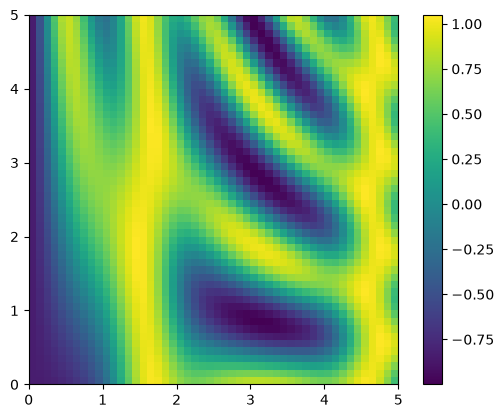

In [205]:
import matplotlib.pyplot as plt

x = np.linspace(0, 5, 50)                     # 50 steps from 0 to 5, as a row
y = np.linspace(0, 5, 50)[:, np.newaxis]      # the same, as a column
z = np.sin(x) ** 10 + np.cos(10 + y * x) * np.cos(x)

plt.imshow(z, origin="lower", extent=[0, 5, 0, 5])
plt.colorbar()
plt.show()

### More aggregations (depth: self-study or if time allows)

Every aggregation exists as a function (`np.sum(x)`) and as a method (`x.sum()`), and almost every one has a version that skips `NaN`:

| Function | NaN-safe version | Result |
|---|---|---|
| `np.sum` | `np.nansum` | sum |
| `np.prod` | `np.nanprod` | product |
| `np.mean` | `np.nanmean` | mean |
| `np.median` | `np.nanmedian` | median |
| `np.std`, `np.var` | `np.nanstd`, `np.nanvar` | standard deviation, variance |
| `np.min`, `np.max` | `np.nanmin`, `np.nanmax` | smallest, largest value |
| `np.argmin`, `np.argmax` | `np.nanargmin`, `np.nanargmax` | position of the smallest, largest value |
| `np.percentile` | `np.nanpercentile` | value below which a given percentage lies |
| `np.any`, `np.all` | | is any / is every element `True`? |

Use NumPy's versions on arrays: Python's built-in `sum`, `min` and `max` loop in Python and are much slower. The next cell applies some of them to the prices of all listings, missing values included.

In [206]:
print(np.nanmin(price), np.nanmax(price))
print(np.nanpercentile(price, [25, 50, 75]))   # quartiles
print(np.nanargmax(price), "is the position of the most expensive listing")
print(np.any(price > 5000), np.all(price > 0))

2.72 10025.0
[ 72.   130.67 207.  ]
8434 is the position of the most expensive listing
True False


The last line shows a pitfall: `np.all(price > 0)` is `False` although no price is zero or negative, because every comparison with `NaN` is `False`. Remove the missing values first when you ask "all".

> 📖 **Read more:** [extras/10-numpy-ufuncs.ipynb](extras/10-numpy-ufuncs.ipynb) and [extras/11-numpy-broadcasting.ipynb](extras/11-numpy-broadcasting.ipynb) (*Python Data Science Handbook*): the original chapters, with diagrams of the broadcasting rules.

## Random numbers and simulation

Simulation answers questions that are hard to compute by hand: roll the dice, or draw the sample, many times and count. NumPy's random numbers come from a **generator** created with `np.random.default_rng(seed)`. The **seed** fixes the sequence, so the notebook gives the same result on every run and on every laptop; without a seed, every run differs.

| Method | Draws |
|---|---|
| `rng.integers(1, 7, size=10)` | 10 whole numbers from 1 to 6 (the upper bound is excluded): ten rolls of a die |
| `rng.random(5)` | 5 floats between 0 and 1 |
| `rng.normal(loc, scale, size)` | values from a normal distribution |
| `rng.choice(values, size, replace=False)` | a random sample from an array |

The next cell rolls a die 10, 100, 10,000 and a million times and prints the share of sixes. **Predict:** how close to 1/6 = 0.167 will 10 rolls be?

In [207]:
rng = np.random.default_rng(42)
print(rng.integers(1, 7, size=10))

for n in [10, 100, 10_000, 1_000_000]:
    rolls = rng.integers(1, 7, size=n)
    print(f"{n:>9,} rolls: share of sixes {(rolls == 6).mean():.3f}")

[1 5 4 3 3 6 1 5 2 1]
       10 rolls: share of sixes 0.200
      100 rolls: share of sixes 0.110
   10,000 rolls: share of sixes 0.163
1,000,000 rolls: share of sixes 0.166


Small samples scatter widely around 1/6; a million rolls are close to it (the *law of large numbers*). The same idea tells us how much a statistic computed from a sample can vary. Suppose we could only check 50 random short-stay listings: how far would their median price be from the median of all 6,701? The next cell draws 1,000 such samples with `rng.choice` and summarises their medians with `np.percentile`.

In [208]:
medians = np.array([np.median(rng.choice(short_price, size=50, replace=False)) for _ in range(1_000)])
print(f"median of all short stays: {np.median(short_price):.0f}")
print(f"medians of 1,000 samples of 50: from {medians.min():.0f} to {medians.max():.0f}")
print(f"middle 90 %: {np.percentile(medians, 5):.0f} to {np.percentile(medians, 95):.0f}")

median of all short stays: 157
medians of 1,000 samples of 50: from 118 to 222
middle 90 %: 134 to 185


One sample in ten gives a median outside the middle 90 % range printed above, more than €20 away from the €157 of all short stays. Session 5 turns this simulation into the bootstrap and confidence intervals.

> **In practice.** Always pass a seed to the generator in analysis code and in the final project, and say how many repetitions a simulation used. Do not use the older `np.random.seed` and `np.random.rand` functions in new code; the NumPy documentation recommends the generator.

### More on random numbers (depth: self-study or if time allows)

**Distributions.** Besides whole numbers, the generator draws from many distributions. `rng.normal(loc, scale, size)` draws from a normal (bell-shaped) distribution with mean `loc` and standard deviation `scale`; `rng.uniform(low, high, size)` draws evenly between two bounds. The next cell draws 100,000 values from a normal distribution with mean 150 and standard deviation 40 and checks that the sample mean and standard deviation are close to these values.

In [209]:
rng = np.random.default_rng(0)
sample = rng.normal(loc=150, scale=40, size=100_000)
print(sample.mean().round(2), sample.std().round(2))
print(rng.uniform(0, 1, size=3))

149.96 40.01
[0.73345778 0.51132272 0.65075373]


**Sampling with and without replacement.** `rng.choice(values, size, replace=False)` never draws the same element twice, like drawing names from a hat; with `replace=True` an element can come back, like rolling a die. Drawing *with* replacement from the data itself is the idea behind the bootstrap of Session 5. `rng.permutation` returns the elements in a random order, which later sessions use to split data into training and test sets.

In [210]:
districts = np.array(["Mitte", "Pankow", "Neukölln", "Spandau", "Lichtenberg"])
print(rng.choice(districts, size=3, replace=False))
print(rng.choice(districts, size=8, replace=True))
print(rng.permutation(districts))

['Spandau' 'Lichtenberg' 'Mitte']
['Mitte' 'Pankow' 'Lichtenberg' 'Spandau' 'Spandau' 'Pankow' 'Spandau'
 'Lichtenberg']
['Neukölln' 'Spandau' 'Pankow' 'Lichtenberg' 'Mitte']


**Same seed, same numbers.** Two generators created with the same seed produce the same sequence, and a new generator starts the sequence again. This is what makes a notebook with simulations reproducible.

In [211]:
print(np.random.default_rng(7).integers(1, 7, size=5))
print(np.random.default_rng(7).integers(1, 7, size=5))   # identical

[6 4 5 6 4]
[6 4 5 6 4]


## Worked example · How far ahead are Berlin listings booked?

The booking calendar of the case study has one row per listing and day: whether the night is still available, for the 365 days that start on the day the listing was scraped. A night that is not available is booked or blocked by the host; the calendar does not say which.

Sorting the rows by listing and date and reshaping the `available` column gives a two-dimensional Boolean array: one row per listing, one column per day ahead. The next cell does this with `sort_values`, `.to_numpy()` and `.reshape(rows, 365)`, and prints a corner of the result.

In [212]:
calendar = pd.read_parquet("case-study/data/airbnb/calendar.parquet")
calendar = calendar.sort_values(["listing_id", "date"])
n_listings = calendar["listing_id"].nunique()

available = calendar["available"].to_numpy().reshape(n_listings, 365)
print(available.shape, available.dtype)
print(available[:3, :10].astype(int))          # three listings, first ten days

(12855, 365) bool
[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 1 1 1 0]
 [0 0 0 1 1 1 1 1 1 1]]


The `reshape` is only correct because every listing has exactly 365 rows, which the case-study script guarantees; on other data check this first (`calendar.groupby("listing_id").size()`, next block). The calendar has 12,855 listings, a few more than the 12,776 in the listings table.

The next cell asks two questions with one aggregation each: `sum(axis=1)` counts the open nights per listing, `mean(axis=0)` gives the share of listings still open per day ahead.

In [213]:
nights_open = available.sum(axis=1)            # per listing: available nights in the next year
print(nights_open.shape, np.median(nights_open), nights_open.mean().round(1))
print((nights_open == 0).mean().round(3), "of the listings have no available night at all")

share_open = available.mean(axis=0)            # per day ahead: share of listings still available
print(share_open.shape)
print(share_open[[0, 7, 30, 90, 180]].round(3))
print("most open:", share_open.argmax(), "days ahead, share", share_open.max().round(3))

(12855,) 137.0 152.9
0.271 of the listings have no available night at all
(365,)
[0.083 0.254 0.372 0.227 0.441]
most open: 172 days ahead, share 0.498


The median listing has 137 available nights in the coming year, and 27 % have none at all: they are fully booked or, much more likely, blocked by hosts who do not rent them out at the moment. On the day of the scrape only 8 % of the listings are still available, a week ahead 25 % and a month ahead 37 %: nearby nights are already booked. Further ahead the share stays between about 35 % and 50 %, with a short dip about 90 days ahead and a maximum of 50 % about 172 days ahead. One line per question, and no loop.

> **In practice.** Before you aggregate, say which axis you collapse and what one value of the result means ("one value per listing", "one value per day"). Most axis mistakes produce an array of the wrong length, which `shape` reveals immediately.

## Check your understanding

1. You run a cell that sets `price = 95`, then a cell above it that computes `price * 3`. What does the page show, and how do you protect yourself from such surprises?
2. What are the `dtype` and the `shape` of `np.array([[1, 2, 3], [4, 5, 6.0]])`?
3. `a = np.arange(5); b = a[1:3]; b[0] = 99`. What is `a` now, and how would you avoid this?
4. An array `X` has shape `(1000, 8)`. What are the shapes of `X.mean(axis=0)`, `X.mean(axis=1)` and `X - X.mean(axis=0)`?
5. Why does `np.median(price)` return `nan` for the listings, and what are two ways to get the median of the prices that are present?

## Exercises (30 min)

Work in pairs. The lecturer picks which exercises to set; predict first, then code. Everything you need is defined in the cells above, so run the notebook from the top before you start.

### 2.1 · Two fees that do not add up

*Predict · 3 min*

> A booking adds two small fees, €1.10 and €2.20. Write down what Python prints for `print(1.10 + 2.20 == 3.30)`. Then run it, and print `1.10 + 2.20` itself.
> Use `help(np.isclose)` to find out how NumPy compares two floats instead, and name one other safe way to compare amounts of money.

*Source:* [Python tutorial: Floating-point arithmetic](https://docs.python.org/3/tutorial/floatingpoint.html)

*Your answer:*

### 2.2 · The alias trap, with lists and arrays

*Predict · 5 min*

> What do the three `print` lines show? Write down your answers, then run the code.
> ```python
> a = [1, 2, 3]
> b = a
> b.append(4)
> print(a)
>
> x = [1, 2, 3]
> y = x[:2]
> y[0] = 99
> print(x)
>
> arr = np.array([1, 2, 3])
> view = arr[:2]
> view[0] = 99
> print(arr)
> ```
> How do you get an independent copy in the first and in the third case?

*Source:* [Python FAQ: Why did changing list y also change list x?](https://docs.python.org/3/faq/programming.html#why-did-changing-list-y-also-change-list-x); the array case: original exercise for this course, background [NumPy user guide: copies and views](https://numpy.org/doc/stable/user/basics.copies.html)

*Your answer:*

### 2.3 · Build and test the budget rule

*Code · 15 min*

> Turn the loop of the Python recap into a reusable function `affordable_districts(records, nights, budget, cleaning_fee=25)` that returns the districts of the available listings whose stay fits the budget. Reuse `stay_cost`.
>
> 1. Trace the recap loop by hand first: which record is skipped because its price is missing, and which because it is not available?
> 2. Make the function reject a non-positive number of nights with a `ValueError`. Why must a missing price not become zero?
> 3. Check your function with `assert` on an empty list, on a stay that costs exactly the budget, and on a listing with a missing price.
> 4. Count the available listings per district with a dictionary, once with a loop and once with a comprehension where it makes sense.

*Source:* original exercise for this course.

### 2.4 · Predict the shape

*Predict · 5 min*

> `cost = np.zeros((4, 7))` stands for the costs of 4 flats for stays of 1 to 7 nights. Write down the shape of each result, or "error". Then check.
>
> 1. `cost.sum(axis=0)` and `cost.sum(axis=1)`, and what one value of each result means
> 2. `cost[:, :2]` and `cost[0]`
> 3. `cost + np.arange(7)`
> 4. `cost + np.arange(4)`. If it fails, how do you add one value per flat instead?

*Source:* original exercise for this course; background: [NumPy user guide: broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html)

*Your answer:*

### 2.5 · Dice simulation

*Code · 10 min*

> Create a generator with a seed of your choice, `rng = np.random.default_rng(...)`, and use no Python loop.
>
> 1. Roll one die 60,000 times. How often does each face come up? (`np.unique(..., return_counts=True)` or `np.bincount`.) How far from 10,000 are your counts?
> 2. Roll two dice 100,000 times (an array of shape `(100_000, 2)`) and add each pair. Which sum is the most frequent, and what is its share? Compare with the exact probability, which you can work out on paper from the 36 equally likely pairs.
> 3. Which sum is the rarest? Is it rarer than you guessed?

*Source:* original exercise for this course; background: [Law of large numbers, Wikipedia](https://en.wikipedia.org/wiki/Law_of_large_numbers)

### 2.6 · Splitting the bill: a price table with broadcasting

*Code · 10 min*

> You and some friends want to stay **3 nights**. Four flats cost 95, 140, 180 and 260 euros a night, plus a one-off cleaning fee of 30, 45, 50 and 80 euros.
>
> 1. Build a table of shape `(4, 6)`: the cost **per person** for each flat (rows) and a group of 1 to 6 people (columns). Use broadcasting, no loop.
> 2. Make a Boolean table: where does each person pay at most €140?
> 3. For each flat, find the smallest group in which everybody pays at most €140. (Hint: `argmax` on a Boolean array returns the position of the first `True`.) Check your result for the most expensive flat. What went wrong, and how do you fix it?

*Source:* original exercise for this course; background: [NumPy user guide: broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html)

In [214]:
nightly = np.array([95, 140, 180, 260])
cleaning_fee = np.array([30, 45, 50, 80])

### 2.7 · A year in the booking calendar

*Pairs · 15 min*

> The Boolean array `available` from the worked example has one row per listing and one column per day, for the 365 days after the listing was scraped (`True`: the night can still be booked).
>
> 1. How many listings have **no** available night in the **next 30 days**? What share is that?
> 2. How many listings are available on **every one** of the 365 days?
> 3. How many listings are available on more than half of the days?
>
> Use slicing, comparisons and aggregation along an axis; no loop. For one answer, say what one value of the intermediate array means ("one value per listing", "one value per day").

*Source:* original exercise for this course, on the Inside Airbnb Berlin snapshot of 26 June 2026 (CC BY 4.0).

In [215]:
available.shape   # rebuilt in the worked example; run it first if this fails

(12855, 365)

### 2.8 · *Stretch:* Rice on a chessboard, NumPy edition

*Predict · 5 min*

> Put 1 grain of rice on the first square of a chessboard, 2 on the second, 4 on the third, doubling on each of the 64 squares. How many grains are on the board in total?
>
> 1. Compute it with Python integers: `sum(2 ** k for k in range(64))`.
> 2. Predict, then run: `(2 ** np.arange(64)).sum()`. Explain the result with the `dtype` of the array.
> 3. Find a `dtype` with which NumPy gives the correct answer.

*Source:* [Wheat and chessboard problem, Wikipedia](https://en.wikipedia.org/wiki/Wheat_and_chessboard_problem); the NumPy part: original exercise for this course, background [NumPy user guide: data types (overflow errors)](https://numpy.org/doc/stable/user/basics.types.html)

## Debrief (15 min)

Compare two or three solutions, one of them wrong, and ask for each result its shape and its unit.

- **Python.** Assignment versus mutation (2.2); `None` versus zero and `return` versus `print` (2.3); catching a known error versus hiding every failure.
- **Shapes.** For 2.4 and 2.7, say what one value of each intermediate array means. Typical mistakes: `axis=0` where one value per listing was wanted, and `available[:30]`, which takes the first 30 *listings*, not days.
- **The bill (2.6).** `argmax` alone cannot tell an all-`False` row from a match in the first position; look for solutions that check `.any(axis=1)`.
- **Simulation (2.5).** `rng.integers(2, 13)` for "two dice" makes every sum equally likely; `integers(1, 6)` never rolls a six.
- **Availability.** A night that is not available is booked *or* blocked; do not call it demand.

**Bridge to the next block.** NumPy arrays have one type and positions only. Real tables have named columns of different types and rows with labels: pandas builds them on top of NumPy, and the same masks, vectorised operations and aggregations come back with names.

**Continue:** [Notebook 3 · pandas: Series and DataFrames](03-lecture-pandas.ipynb).

## Further reading

- Python Software Foundation (2026). *The Python Tutorial*, sections 3–5. https://docs.python.org/3/tutorial/
- VanderPlas, J. (2016). *A Whirlwind Tour of Python*. O'Reilly, CC0. https://jakevdp.github.io/WhirlwindTourOfPython/ (extras 02–08; the list-indexing figure).
- Downey, A. B. (2024). *Think Python*, 3rd edition. O'Reilly. https://allendowney.github.io/ThinkPython/ (extra 01).
- Project Jupyter (2026). *JupyterLab documentation: notebooks*. https://jupyterlab.readthedocs.io/en/stable/user/notebook.html
- Astral (2026). *uv documentation: working on projects*. https://docs.astral.sh/uv/guides/projects/
- NumPy developers (2026). *NumPy: the absolute basics for beginners*. https://numpy.org/doc/stable/user/absolute_beginners.html
- NumPy developers (2026). *Broadcasting* and *Random sampling* (the `Generator` interface). https://numpy.org/doc/stable/user/basics.broadcasting.html, https://numpy.org/doc/stable/reference/random/index.html
- McKinney, W. (2022). *Python for Data Analysis*, 3rd edition, chapter 4 (NumPy basics: arrays and vectorised computation). Open access. https://wesmckinney.com/book/
- VanderPlas, J. (2022). *Python Data Science Handbook*, 2nd edition, chapter 2 (introduction to NumPy). O'Reilly. https://jakevdp.github.io/PythonDataScienceHandbook/ (extras 09–11).
- Inside Airbnb (2026). Berlin, snapshot of 26 June 2026. CC BY 4.0. https://insideairbnb.com/get-the-data/

All extras and their licences: [extras/README.md](extras/README.md). This notebook is course material, CC BY 4.0.